# BÀI 4. XÂY DỰNG MÔ HÌNH MLP CHO DỮ LIỆU ẢNH
## Trọng tâm: Workflow Deep Learning hoàn chỉnh

**Mục tiêu bài thực hành**

Sau bài này, sinh viên có thể:

1. Hiểu dữ liệu ảnh được biểu diễn dưới dạng tensor như thế nào.
2. Tách dữ liệu thành **training / validation / test** đúng vai trò.
3. Tiền xử lý dữ liệu phù hợp cho mạng nơ-ron.
4. Xây dựng một mô hình **Multi-Layer Perceptron (MLP)** bằng TensorFlow/Keras.
5. Hiểu quy trình **compile → train → validate → evaluate → predict**.
6. Theo dõi quá trình học qua **loss curve** và **accuracy curve**.
7. Nhận biết dấu hiệu **underfitting / overfitting**.
8. Sử dụng callback như **EarlyStopping** và **ModelCheckpoint**.
9. Đánh giá mô hình bằng accuracy, confusion matrix và classification report.
10. Thực hiện inference trên ảnh mới và lưu/khôi phục mô hình.

---

### Bộ dữ liệu sử dụng: Fashion-MNIST

Fashion-MNIST gồm ảnh xám kích thước **28×28**, thuộc **10 lớp** trang phục.

Bộ dữ liệu này phù hợp để học MLP vì:
- dữ liệu đủ nhỏ để huấn luyện nhanh trên Colab;
- khó hơn MNIST chữ số;
- ảnh có cấu trúc rõ ràng;
- MLP có thể xử lý trực tiếp sau khi làm phẳng ảnh thành vector.

> **Lưu ý:** MLP không khai thác tốt cấu trúc không gian của ảnh như CNN. Trong bài này, MLP được dùng để tập trung vào **workflow của Deep Learning**. CNN sẽ là bước tiếp theo tự nhiên.

---

**BẢN NỘP BÀI THỰC HÀNH**

Bản làm bám theo notebook “Bài 4. MLP với dữ liệu ảnh”. Mục 1–21 thực hiện workflow của bài giảng. Mục 23 giải 10 câu thảo luận. Mục 24–29 giải sáu bài mở rộng. Mục 30 trả lời tám nội dung báo cáo ngắn. Mục 31 đối chiếu toàn bộ yêu cầu với kết quả.

Mở notebook và chạy các ô từ trên xuống. Thư mục `ket_qua` được tạo cạnh notebook để lưu bảng CSV, biểu đồ, lịch sử học, dự đoán và các mô hình `.keras`. Các kết quả cũng được hiển thị sẵn trong notebook. Chạy lần đầu cần Internet để Keras tải Fashion-MNIST. Phiên bản thư viện của lần chạy đã lưu được ghi ở mục 1 và trong `requirements.txt`.

Các lựa chọn đề để mở gồm lớp ẩn thứ ba có 64 neuron và hệ số L2 bằng `1e-4`, áp dụng ở hai Dense ẩn. Các thí nghiệm dùng MLP, Dense, ReLU, Softmax, Adam, tf.data, callback, Dropout và L2 theo nội dung bài. Chỉ số và nhận xét được tính lại từ kết quả khi chạy notebook.


## 1. Chuẩn bị môi trường và thư viện

Trong Deep Learning, chúng ta thường cần:

- thư viện xử lý số liệu;
- thư viện trực quan hóa;
- framework Deep Learning;
- công cụ đánh giá mô hình.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

from time import perf_counter
from IPython.display import Markdown, display
import sklearn

OUTPUT_DIR = "ket_qua"
os.makedirs(OUTPUT_DIR, exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", None)

environment = pd.DataFrame({
    "Thư viện": ["TensorFlow", "Keras", "NumPy", "pandas", "Matplotlib", "scikit-learn"],
    "Phiên bản": [tf.__version__, tf.keras.__version__, np.__version__, pd.__version__,
                 plt.matplotlib.__version__, sklearn.__version__],
})
display(environment)
environment.to_csv(os.path.join(OUTPUT_DIR, "moi_truong.csv"), index=False, encoding="utf-8-sig")
requirements = ["tensorflow==" + tf.__version__, "keras==" + tf.keras.__version__, "numpy==" + np.__version__,
                "pandas==" + pd.__version__, "matplotlib==" + plt.matplotlib.__version__,
                "scikit-learn==" + sklearn.__version__]
with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write("\n".join(requirements) + "\n")


TensorFlow version: 2.21.0
GPU available: []


,Thư viện,Phiên bản
0,TensorFlow,2.21.0
1,Keras,3.15.1
2,NumPy,2.5.4
3,pandas,3.0.6
4,Matplotlib,3.11.2
5,scikit-learn,1.9.1


### Hướng dẫn đọc kết quả

- `TensorFlow version` cho biết phiên bản framework đang sử dụng.
- `GPU available` cho biết Colab có nhận GPU hay không.
- Với Fashion-MNIST và MLP nhỏ, CPU vẫn có thể chạy được; tuy nhiên GPU giúp huấn luyện nhanh hơn.

### Phân tích thực tế

Trong các dự án Deep Learning lớn, môi trường tính toán ảnh hưởng trực tiếp đến thời gian huấn luyện. Vì vậy, kiểm tra GPU là một bước quen thuộc trước khi bắt đầu.

## 2. Thiết lập random seed để tăng khả năng tái lập kết quả

Deep Learning có nhiều yếu tố ngẫu nhiên:
- khởi tạo trọng số;
- thứ tự mini-batch;
- một số phép toán trên GPU.

Đặt seed giúp các lần chạy cho kết quả gần nhau hơn.

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed =", SEED)

Random seed = 42


### Hướng dẫn đọc kết quả

Nếu notebook được chạy lại với cùng seed, quá trình huấn luyện thường cho kết quả gần tương tự.

### Phân tích thực tế

Không nên hiểu seed là đảm bảo 100% mọi lần chạy giống hệt nhau trên mọi phần cứng. Tuy nhiên, đây là bước quan trọng để thí nghiệm có tính **reproducibility**.

## 3. Tải dữ liệu Fashion-MNIST

Keras cung cấp sẵn Fashion-MNIST nên không cần tải file thủ công.

Dữ liệu gốc đã được chia thành:
- **60,000 ảnh training**
- **10,000 ảnh test**

Sau đó ta sẽ tiếp tục tách một phần training thành validation.

In [3]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("X_train_full:", X_train_full.shape)
print("y_train_full:", y_train_full.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Kiểu dữ liệu ảnh:", X_train_full.dtype)
print("Khoảng giá trị pixel:", X_train_full.min(), "->", X_train_full.max())

X_train_full: (60000, 28, 28)
y_train_full: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)
Kiểu dữ liệu ảnh: uint8
Khoảng giá trị pixel: 0 -> 255


### Hướng dẫn đọc kết quả

- `(60000, 28, 28)` nghĩa là có 60,000 ảnh, mỗi ảnh kích thước 28×28.
- Nhãn có dạng vector 1 chiều, mỗi phần tử là một số nguyên từ 0 đến 9.
- Pixel ảnh gốc nằm trong khoảng **0–255**.

### Phân tích thực tế

Ảnh không phải là một bảng feature được thiết kế sẵn như bài hồi quy hay classification trước. Mỗi pixel chính là một giá trị đầu vào. Đây là điểm chuyển quan trọng từ dữ liệu bảng sang dữ liệu ảnh.

## 4. Khám phá nhanh dữ liệu ảnh

Ở bài này chúng ta **không tập trung vào EDA sâu** như với dữ liệu bảng.  
Mục đích của bước này chỉ là:

1. hiểu ảnh trông như thế nào;
2. kiểm tra nhãn;
3. kiểm tra phân bố lớp;
4. xác nhận dữ liệu hợp lý trước khi huấn luyện.

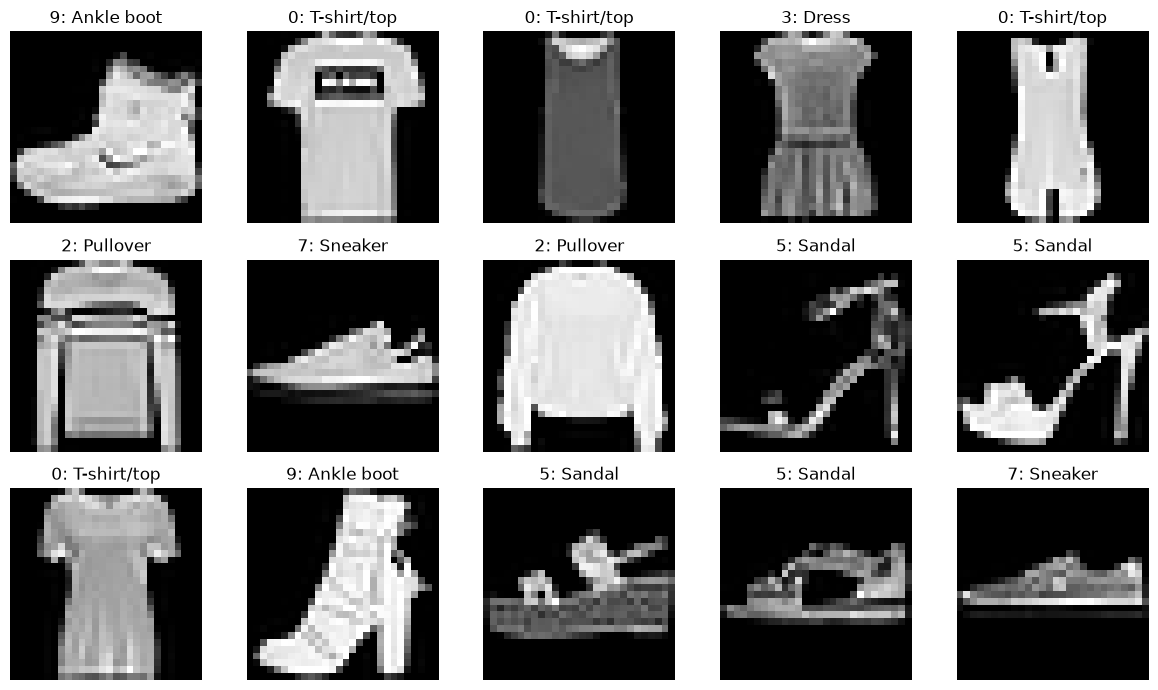

In [4]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_full[i], cmap="gray")
    ax.set_title(f"{y_train_full[i]}: {class_names[y_train_full[i]]}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "anh_du_lieu.png"), bbox_inches="tight", dpi=140)
plt.show()

### Hướng dẫn đọc kết quả

Mỗi ảnh được hiển thị cùng:
- mã nhãn;
- tên lớp tương ứng.

### Phân tích thực tế

Ảnh Fashion-MNIST khá nhỏ và không chứa màu. Một số lớp có hình dạng gần nhau như:
- `T-shirt/top`;
- `Shirt`;
- `Pullover`;
- `Coat`.

Do đó đây là bài toán khó hơn nhận dạng chữ số MNIST.

In [5]:
unique, counts = np.unique(y_train_full, return_counts=True)

class_distribution = pd.DataFrame({
    "class_id": unique,
    "class_name": [class_names[i] for i in unique],
    "count": counts
})

display(class_distribution)
class_distribution.to_csv(os.path.join(OUTPUT_DIR, "phan_bo_lop_goc.csv"), index=False, encoding="utf-8-sig")

,class_id,class_name,count
0,0,T-shirt/top,6000
1,1,Trouser,6000
2,2,Pullover,6000
3,3,Dress,6000
4,4,Coat,6000
5,5,Sandal,6000
6,6,Shirt,6000
7,7,Sneaker,6000
8,8,Bag,6000
9,9,Ankle boot,6000


### Hướng dẫn đọc kết quả

Bảng cho biết số mẫu của từng lớp.

### Phân tích thực tế

Fashion-MNIST được xây dựng khá cân bằng, nên ở bài này **không cần sampling để xử lý class imbalance** như bài 3. Điều đó giúp ta tập trung vào quy trình huấn luyện Deep Learning.

## 5. Tách Training / Validation / Test

Trong Deep Learning, ba tập dữ liệu có vai trò khác nhau:

- **Training set**: dùng để cập nhật trọng số mô hình bằng gradient descent.
- **Validation set**: dùng để theo dõi khả năng tổng quát hóa trong quá trình huấn luyện và lựa chọn epoch/hyperparameter.
- **Test set**: chỉ dùng ở cuối để đánh giá mô hình đã hoàn thiện.

> Không nên dùng test set để điều chỉnh mô hình.

In [6]:
VAL_SIZE = 10_000

X_val = X_train_full[-VAL_SIZE:]
y_val = y_train_full[-VAL_SIZE:]

X_train = X_train_full[:-VAL_SIZE]
y_train = y_train_full[:-VAL_SIZE]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

split_distribution = pd.DataFrame({
    "Lớp": class_names,
    "Train": np.bincount(y_train, minlength=10),
    "Validation": np.bincount(y_val, minlength=10),
    "Test": np.bincount(y_test, minlength=10),
})
display(split_distribution)
split_distribution.to_csv(os.path.join(OUTPUT_DIR, "phan_bo_train_val_test.csv"), index=False, encoding="utf-8-sig")


Training: (50000, 28, 28) (50000,)
Validation: (10000, 28, 28) (10000,)
Test: (10000, 28, 28) (10000,)


,Lớp,Train,Validation,Test
0,T-shirt/top,4977,1023,1000
1,Trouser,5012,988,1000
2,Pullover,4992,1008,1000
3,Dress,4979,1021,1000
4,Coat,4950,1050,1000
5,Sandal,5004,996,1000
6,Shirt,5030,970,1000
7,Sneaker,5045,955,1000
8,Bag,5032,968,1000
9,Ankle boot,4979,1021,1000


### Hướng dẫn đọc kết quả

Ta thu được:
- 50,000 mẫu training;
- 10,000 mẫu validation;
- 10,000 mẫu test.

### Phân tích thực tế

Validation set đóng vai trò rất quan trọng trong Deep Learning vì một mô hình có thể tiếp tục giảm training loss nhưng bắt đầu tăng validation loss. Đó là dấu hiệu overfitting.

## 6. Chuẩn hóa dữ liệu ảnh

Mỗi pixel ban đầu nằm trong khoảng `[0, 255]`.

Ta chuyển sang `float32` và chia cho 255 để đưa dữ liệu về `[0, 1]`.

Việc chuẩn hóa giúp:
- gradient ổn định hơn;
- tối ưu dễ hơn;
- các layer nhận dữ liệu ở thang đo phù hợp.

In [7]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training min/max:", X_train.min(), X_train.max())
print("Validation min/max:", X_val.min(), X_val.max())
print("Test min/max:", X_test.min(), X_test.max())

Training min/max: 0.0 1.0
Validation min/max: 0.0 1.0
Test min/max: 0.0 1.0


### Hướng dẫn đọc kết quả

Sau chuẩn hóa:
- giá trị nhỏ nhất ≈ 0;
- giá trị lớn nhất ≈ 1.

### Phân tích thực tế

Trong Deep Learning, scale dữ liệu thường ảnh hưởng mạnh đến tốc độ hội tụ. Với ảnh xám, chia cho 255 là cách chuẩn hóa đơn giản và hiệu quả.

## 7. Tạo input pipeline bằng `tf.data`

Deep Learning thường huấn luyện bằng **mini-batch**, không đưa toàn bộ dữ liệu vào mô hình cùng lúc.

`tf.data.Dataset` giúp:
- tạo batch;
- shuffle dữ liệu;
- prefetch dữ liệu;
- xây dựng pipeline có thể mở rộng cho dữ liệu lớn.

In [8]:
BATCH_SIZE = 64

def make_train_dataset(batch_size):
    return (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(buffer_size=len(X_train), seed=SEED)
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )

train_ds = make_train_dataset(BATCH_SIZE)
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
)
test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
)
train_eval_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
)

for images, labels in train_ds.take(1):
    print("Batch images shape:", images.shape)
    print("Batch labels shape:", labels.shape)

# Tạo lại pipeline sau ô minh họa để bắt đầu train từ lượt shuffle đầu.
train_ds = make_train_dataset(BATCH_SIZE)

Batch images shape: (64, 28, 28)
Batch labels shape: (64,)


### Hướng dẫn đọc kết quả

Một batch có dạng:

- ảnh: `(batch_size, 28, 28)`
- nhãn: `(batch_size,)`

### Phân tích thực tế

Mini-batch là đơn vị cơ bản của quá trình huấn luyện Deep Learning. Mỗi batch đi qua:
1. forward pass;
2. tính loss;
3. backpropagation;
4. cập nhật trọng số.

Sau khi đi hết mọi batch, ta hoàn thành **1 epoch**.

## 8. Xây dựng mô hình MLP

Ảnh có dạng ma trận `28 × 28`.  
MLP yêu cầu vector đầu vào, nên trước hết cần **Flatten** ảnh:

\[
28 \times 28 = 784
\]

Sau đó dữ liệu đi qua các Dense layer:

\[
784 \rightarrow 256 \rightarrow 128 \rightarrow 10
\]

Layer cuối có 10 neuron, tương ứng 10 lớp.

In [9]:
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 235,146 (918.54 KB)
 Trainable params: 235,146 (918.54 KB)
 Non-trainable params: 0 (0.00 B)


### Hướng dẫn đọc kết quả

`model.summary()` cho biết:
- tên từng layer;
- kích thước output;
- số parameter cần học.

Dense layer có số tham số:

`input_size × output_size + bias`

### Phân tích thực tế

Số parameter của MLP có thể khá lớn dù ảnh chỉ 28×28. Nguyên nhân là mỗi neuron Dense kết nối với toàn bộ đầu vào. Đây cũng là một lý do CNN thường hiệu quả hơn cho dữ liệu ảnh.

## 9. Compile mô hình

Trước khi train, cần xác định ba thành phần:

1. **Optimizer** – cách cập nhật trọng số.
2. **Loss function** – hàm mục tiêu cần tối thiểu hóa.
3. **Metric** – chỉ số theo dõi hiệu năng.

Ở đây sử dụng:

- Optimizer: `Adam`
- Loss: `SparseCategoricalCrossentropy`
- Metric: `accuracy`

Vì nhãn được lưu dưới dạng số nguyên `0...9`, ta dùng **sparse categorical cross-entropy**.

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


### Hướng dẫn đọc kết quả

Nếu cell chạy không lỗi, mô hình đã sẵn sàng để huấn luyện.

### Phân tích thực tế

`compile()` không huấn luyện mô hình. Nó chỉ thiết lập quy tắc huấn luyện. Việc cập nhật trọng số chỉ xảy ra khi gọi `fit()`.

## 10. Callback trong Deep Learning

Huấn luyện mạng nơ-ron có thể kéo dài nhiều epoch. Callback giúp kiểm soát quá trình này.

Ta sử dụng:

### EarlyStopping
Dừng huấn luyện khi validation loss không còn cải thiện.

### ModelCheckpoint
Lưu lại mô hình có validation loss tốt nhất.

Đây là workflow phổ biến trong thực tế để tránh giữ mô hình ở epoch cuối nếu epoch đó đã overfit.

In [11]:
checkpoint_path = os.path.join(OUTPUT_DIR, "best_mlp_fashion.keras")

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

print("Callbacks ready.")

Callbacks ready.


## 11. Huấn luyện mô hình

Trong mỗi epoch:

1. mô hình chạy qua toàn bộ training set;
2. optimizer cập nhật trọng số theo từng mini-batch;
3. cuối epoch, mô hình được đánh giá trên validation set.

Ta theo dõi đồng thời:
- `loss`;
- `accuracy`;
- `val_loss`;
- `val_accuracy`.

In [12]:
EPOCHS = 40

baseline_start = perf_counter()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=2,
    shuffle=False
)
baseline_fit_seconds = perf_counter() - baseline_start

Epoch 1/40
782/782 - 2s - 3ms/step - accuracy: 0.8198 - loss: 0.5043 - val_accuracy: 0.8595 - val_loss: 0.3972
Epoch 2/40
782/782 - 1s - 2ms/step - accuracy: 0.8651 - loss: 0.3693 - val_accuracy: 0.8611 - val_loss: 0.3757
Epoch 3/40
782/782 - 1s - 2ms/step - accuracy: 0.8783 - loss: 0.3289 - val_accuracy: 0.8650 - val_loss: 0.3793
Epoch 4/40
782/782 - 2s - 2ms/step - accuracy: 0.8872 - loss: 0.3045 - val_accuracy: 0.8794 - val_loss: 0.3427
Epoch 5/40
782/782 - 1s - 2ms/step - accuracy: 0.8934 - loss: 0.2866 - val_accuracy: 0.8823 - val_loss: 0.3274
Epoch 6/40
782/782 - 2s - 2ms/step - accuracy: 0.8989 - loss: 0.2715 - val_accuracy: 0.8839 - val_loss: 0.3178
Epoch 7/40
782/782 - 2s - 2ms/step - accuracy: 0.9027 - loss: 0.2609 - val_accuracy: 0.8745 - val_loss: 0.3555
Epoch 8/40
782/782 - 1s - 2ms/step - accuracy: 0.9073 - loss: 0.2484 - val_accuracy: 0.8726 - val_loss: 0.3572
Epoch 9/40
782/782 - 2s - 2ms/step - accuracy: 0.9094 - loss: 0.2390 - val_accuracy: 0.8891 - val_loss: 0.3056
E

### Hướng dẫn đọc kết quả

Mỗi dòng epoch thường có:

- `loss`: training loss;
- `accuracy`: training accuracy;
- `val_loss`: validation loss;
- `val_accuracy`: validation accuracy.

### Phân tích thực tế

Một quá trình học tốt thường có:
- training loss giảm;
- validation loss cũng giảm trong giai đoạn đầu;
- accuracy tăng dần.

Nếu training loss tiếp tục giảm nhưng validation loss tăng, mô hình đang **overfitting**.

## 12. Trực quan hóa learning curves

Learning curve là công cụ quan trọng để đọc quá trình huấn luyện Deep Learning.

Ta sẽ vẽ:
- Loss theo epoch;
- Accuracy theo epoch.

In [13]:
history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "Epoch"
display(history_df.round(6))
history_df.to_csv(os.path.join(OUTPUT_DIR, "history_mlp_goc.csv"), encoding="utf-8-sig")

,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.81978,0.504334,0.8595,0.397196
2,0.86506,0.369346,0.8611,0.375731
3,0.87830,0.328895,0.8650,0.379279
4,0.88724,0.304515,0.8794,0.342728
5,0.89342,0.286613,0.8823,0.327405
6,0.89892,0.271467,0.8839,0.317844
7,0.90268,0.260887,0.8745,0.355458
8,0.90728,0.248432,0.8726,0.357216
9,0.90938,0.238986,0.8891,0.305609


### Hướng dẫn đọc kết quả

Mỗi dòng tương ứng một epoch.  
Bảng này là dữ liệu nguồn để phân tích quá trình học.

### Phân tích thực tế

Không nên chỉ nhìn accuracy cuối cùng. Lịch sử training giúp ta biết:
- mô hình học nhanh hay chậm;
- bắt đầu overfit ở epoch nào;
- callback có dừng hợp lý không.

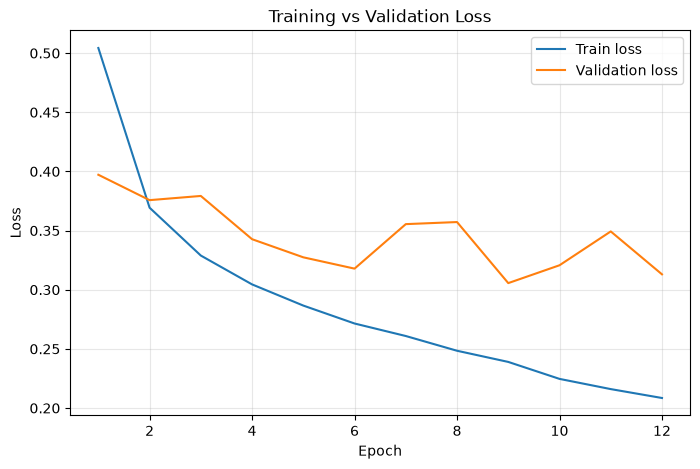

In [14]:
epoch_numbers = history_df.index
plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, history.history["loss"], label="Train loss")
plt.plot(epoch_numbers, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, "loss_mlp_goc.png"), bbox_inches="tight", dpi=140)
plt.show()

### Hướng dẫn đọc kết quả

- Đường train loss cho biết mức lỗi trên training set.
- Đường validation loss cho biết khả năng tổng quát hóa trên dữ liệu chưa dùng để cập nhật trọng số.

### Phân tích thực tế

- Hai đường cùng giảm: mô hình đang học tốt.
- Train loss giảm nhưng val loss tăng: overfitting.
- Cả hai đều cao và gần nhau: có thể underfitting.

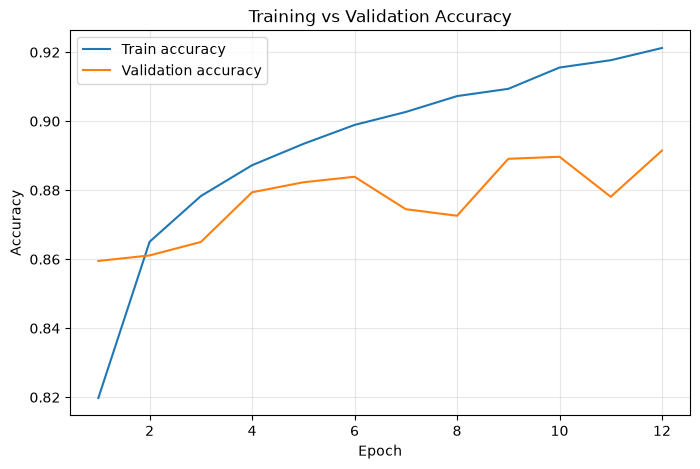

In [15]:
epoch_numbers = history_df.index
plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, history.history["accuracy"], label="Train accuracy")
plt.plot(epoch_numbers, history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_mlp_goc.png"), bbox_inches="tight", dpi=140)
plt.show()

### Hướng dẫn đọc kết quả

So sánh khoảng cách giữa training accuracy và validation accuracy.

### Phân tích thực tế

Khoảng cách nhỏ thường cho thấy mô hình tổng quát hóa tương đối tốt. Nếu training accuracy cao hơn validation accuracy quá nhiều, mô hình có thể đang ghi nhớ training set.

## 13. Đánh giá cuối cùng trên Test Set

Sau khi quá trình train và lựa chọn mô hình hoàn tất, ta mới đánh giá trên test set.

Test set đóng vai trò như dữ liệu hoàn toàn mới.

In [16]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")

Test loss     : 0.3242
Test accuracy : 0.8862


### Hướng dẫn đọc kết quả

`Test accuracy` là tỷ lệ dự đoán đúng trên dữ liệu test.

### Phân tích thực tế

Nếu validation accuracy và test accuracy gần nhau, kết quả validation có khả năng phản ánh tốt khả năng tổng quát hóa. Nếu test accuracy giảm mạnh, quy trình tuning có thể đã phụ thuộc quá nhiều vào validation set.

## 14. Dự đoán xác suất và nhãn lớp

Layer cuối dùng Softmax nên mô hình trả về một vector xác suất cho 10 lớp.

Ví dụ:

`[0.01, 0.00, 0.02, ..., 0.90]`

Lớp có xác suất lớn nhất được chọn làm dự đoán.

In [17]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Probability shape:", y_prob.shape)
print("5 nhãn thật đầu tiên:", y_test[:5])
print("5 nhãn dự đoán đầu tiên:", y_pred[:5])

Probability shape: (10000, 10)
5 nhãn thật đầu tiên: [9 2 1 1 6]
5 nhãn dự đoán đầu tiên: [9 2 1 1 6]


### Hướng dẫn đọc kết quả

- `y_prob.shape = (10000, 10)` nghĩa là mỗi ảnh có 10 xác suất.
- `argmax` lấy vị trí có xác suất lớn nhất làm nhãn dự đoán.

### Phân tích thực tế

Trong nhiều ứng dụng, xác suất dự đoán cũng quan trọng như nhãn cuối cùng vì nó cho biết độ tự tin tương đối của mô hình.

## 15. Confusion Matrix

Accuracy cho biết hiệu quả tổng thể, nhưng không cho biết mô hình nhầm lớp nào với lớp nào.

Confusion matrix giúp phân tích lỗi chi tiết hơn.

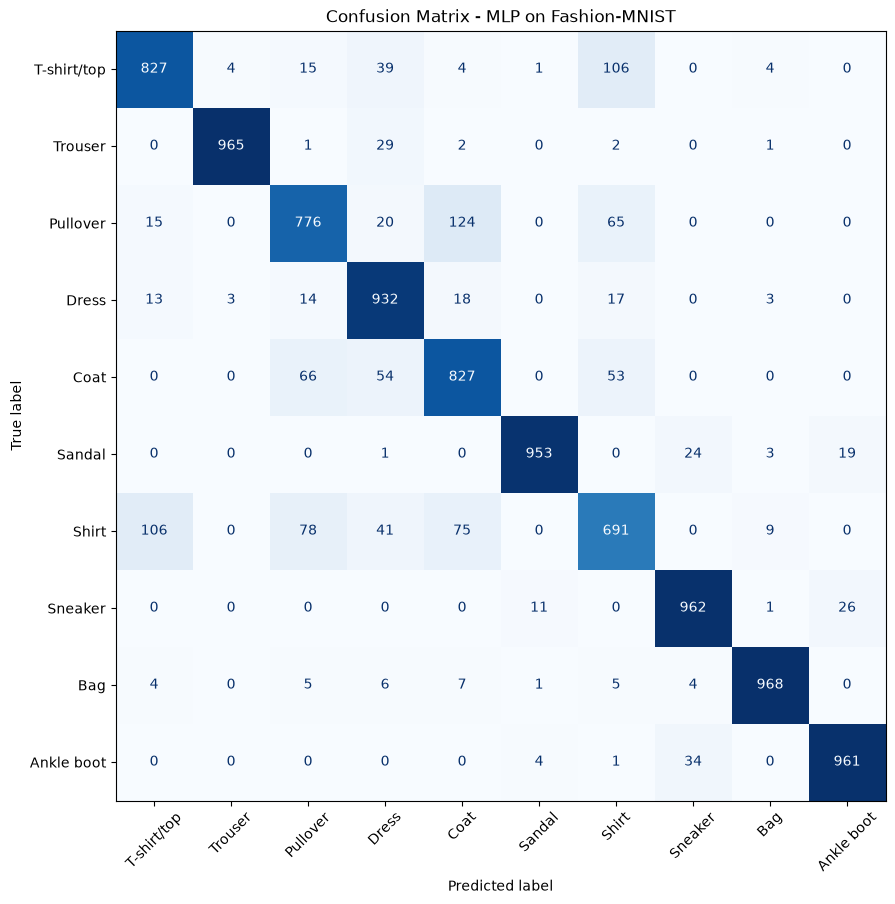

In [18]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - MLP on Fashion-MNIST")
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_mlp_goc.png"), bbox_inches="tight", dpi=140)
plt.show()
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(os.path.join(OUTPUT_DIR, "confusion_matrix_mlp_goc.csv"), encoding="utf-8-sig")

### Hướng dẫn đọc kết quả

- Giá trị trên đường chéo: số mẫu dự đoán đúng.
- Giá trị ngoài đường chéo: các trường hợp bị nhầm lớp.

### Phân tích thực tế

Với Fashion-MNIST, mô hình thường dễ nhầm các nhóm có hình dạng tương tự nhau như:
- Shirt và T-shirt/top;
- Shirt và Pullover;
- Coat và Pullover.

Confusion matrix cho phép nhìn rõ loại lỗi này hơn accuracy.

## 16. Classification Report

Ta xem thêm:
- precision;
- recall;
- F1-score;
- support.

Mục tiêu ở đây không phải học lại toàn bộ metric của bài 3, mà là biết cách kiểm tra hiệu năng theo từng lớp.

In [19]:
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

report_data = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
report_data.pop("accuracy")
report_table = pd.DataFrame(report_data).T
display(report_table.round(6))
report_table.to_csv(os.path.join(OUTPUT_DIR, "classification_report_mlp_goc.csv"), encoding="utf-8-sig")
predictions = pd.DataFrame({
    "test_index": np.arange(len(y_test)), "true_label": y_test,
    "predicted_label": y_pred, "confidence": y_prob.max(axis=1),
})
for class_id, class_name in enumerate(class_names):
    predictions["p_" + class_name] = y_prob[:, class_id]
predictions.to_csv(os.path.join(OUTPUT_DIR, "du_doan_test_mlp_goc.csv"), index=False, encoding="utf-8-sig")


              precision    recall  f1-score   support

 T-shirt/top     0.8570    0.8270    0.8417      1000
     Trouser     0.9928    0.9650    0.9787      1000
    Pullover     0.8126    0.7760    0.7939      1000
       Dress     0.8307    0.9320    0.8784      1000
        Coat     0.7824    0.8270    0.8041      1000
      Sandal     0.9825    0.9530    0.9675      1000
       Shirt     0.7351    0.6910    0.7124      1000
     Sneaker     0.9395    0.9620    0.9506      1000
         Bag     0.9788    0.9680    0.9734      1000
  Ankle boot     0.9553    0.9610    0.9581      1000

    accuracy                         0.8862     10000
   macro avg     0.8866    0.8862    0.8859     10000
weighted avg     0.8866    0.8862    0.8859     10000



,precision,recall,f1-score,support
T-shirt/top,0.856995,0.8270,0.841730,1000.0
Trouser,0.992798,0.9650,0.978702,1000.0
Pullover,0.812565,0.7760,0.793862,1000.0
Dress,0.830660,0.9320,0.878417,1000.0
Coat,0.782403,0.8270,0.804084,1000.0
Sandal,0.982474,0.9530,0.967513,1000.0
Shirt,0.735106,0.6910,0.712371,1000.0
Sneaker,0.939453,0.9620,0.950593,1000.0
Bag,0.978766,0.9680,0.973353,1000.0
Ankle boot,0.955268,0.9610,0.958126,1000.0


### Hướng dẫn đọc kết quả

- `precision`: trong các mẫu mô hình dự đoán là một lớp, bao nhiêu mẫu đúng.
- `recall`: trong các mẫu thực sự thuộc lớp đó, mô hình tìm đúng bao nhiêu.
- `f1-score`: cân bằng precision và recall.

### Phân tích thực tế

Dù dữ liệu cân bằng, một số lớp vẫn có F1 thấp hơn vì bản thân hình ảnh giữa các lớp đó khó phân biệt.

## 17. Trực quan hóa các dự đoán

Ta hiển thị một số ảnh cùng:
- nhãn thật;
- nhãn dự đoán;
- xác suất cao nhất.

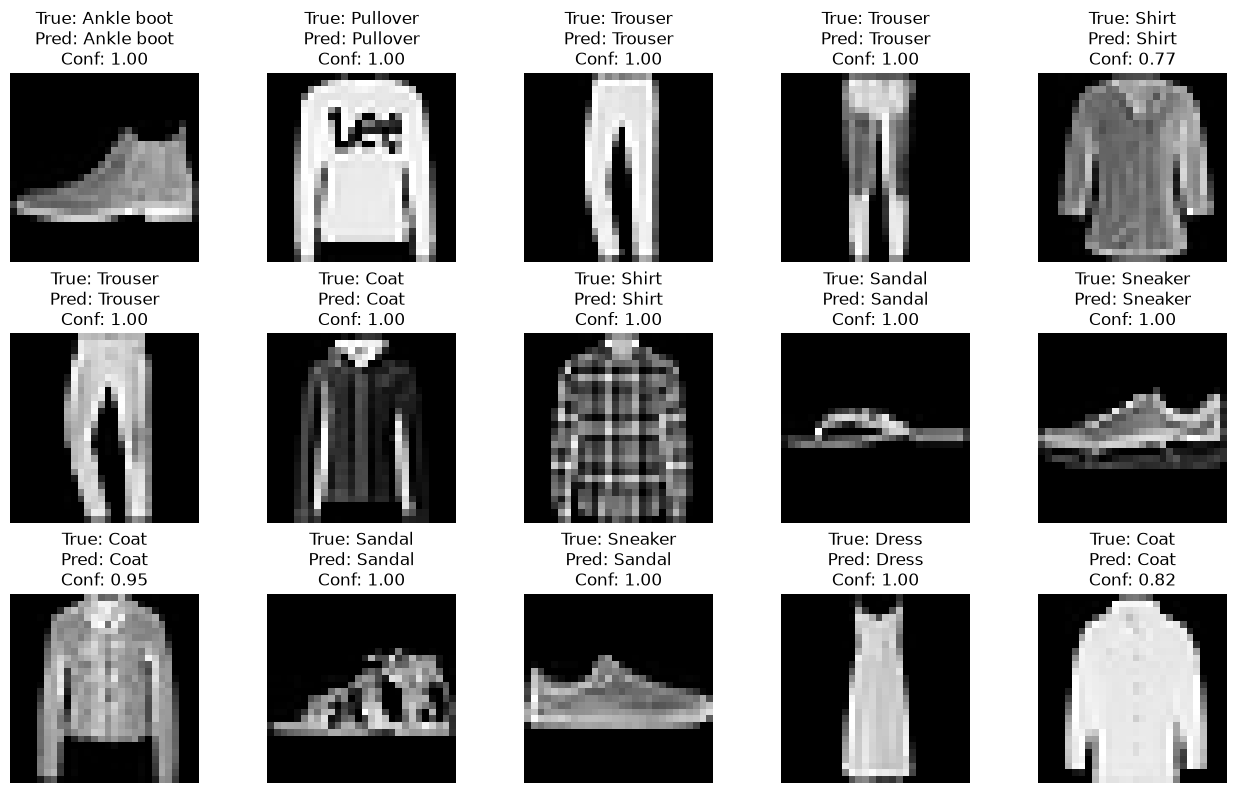

In [20]:
indices = np.arange(15)

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for idx, ax in zip(indices, axes.ravel()):
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_prob[idx][pred_label]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {confidence:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "du_doan_15_anh.png"), bbox_inches="tight", dpi=140)
plt.show()

### Hướng dẫn đọc kết quả

Mỗi ảnh cho biết:
- lớp thật;
- lớp mô hình chọn;
- confidence của lớp được chọn.

### Phân tích thực tế

Các mẫu dự đoán sai nhưng confidence cao là những ví dụ rất quan trọng để phân tích lỗi mô hình. Trong các bài toán thực tế, đây thường là nhóm cần được điều tra sâu hơn.

## 18. Phân tích các mẫu dự đoán sai

Thay vì chỉ xem accuracy, ta chủ động tìm các ảnh mà mô hình dự đoán sai.

Số mẫu dự đoán sai: 1138


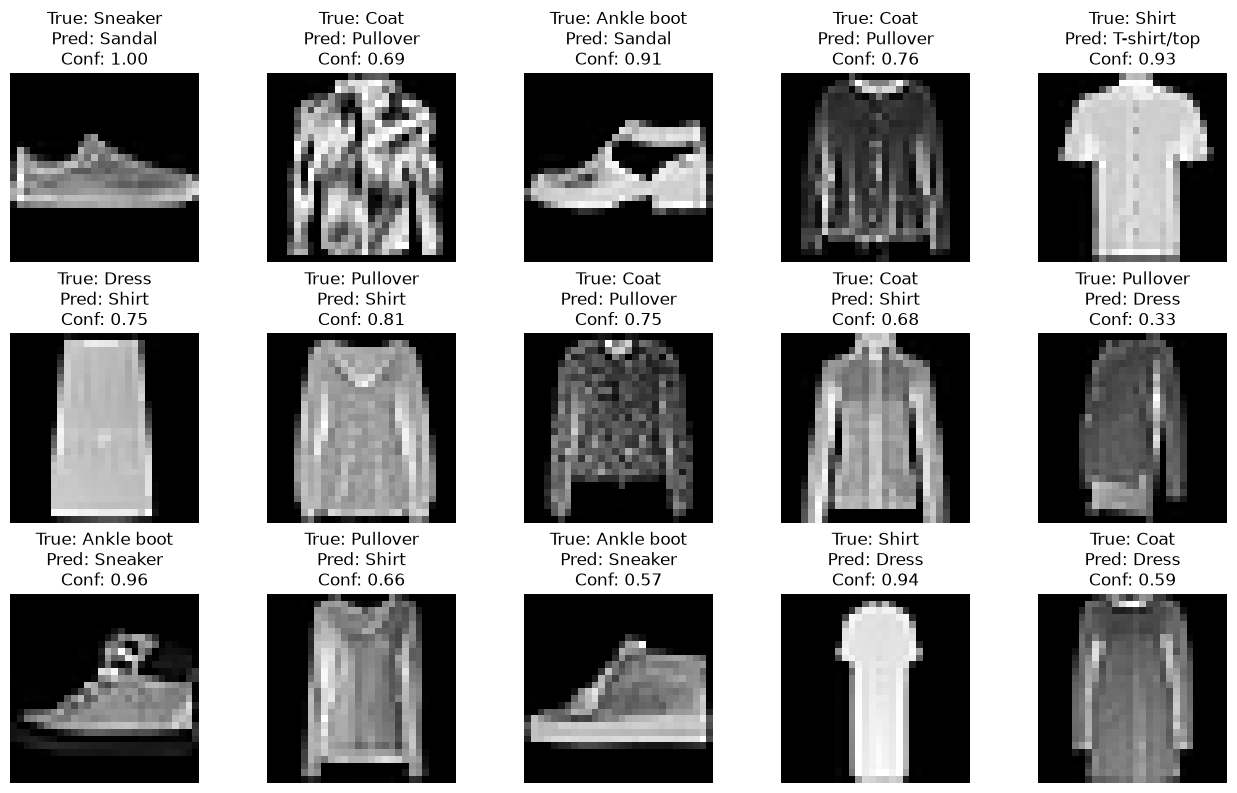

In [21]:
wrong_indices = np.where(y_pred != y_test)[0]

print("Số mẫu dự đoán sai:", len(wrong_indices))

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for idx, ax in zip(wrong_indices[:15], axes.ravel()):
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_prob[idx][pred_label]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {confidence:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "du_doan_sai_15_anh.png"), bbox_inches="tight", dpi=140)
plt.show()

### Hướng dẫn đọc kết quả

Chỉ các mẫu mô hình dự đoán sai được hiển thị.

### Phân tích thực tế

Error analysis là bước quan trọng của workflow Deep Learning. Từ lỗi thực tế, ta mới quyết định có cần:
- mô hình sâu hơn;
- regularization;
- thêm dữ liệu;
- data augmentation;
- đổi kiến trúc sang CNN.

## 19. Inference trên một ảnh riêng lẻ

Trong thực tế, mô hình thường nhận một hoặc một vài mẫu mới chứ không phải cả test set.

Ta chọn một ảnh và mô phỏng quy trình inference.

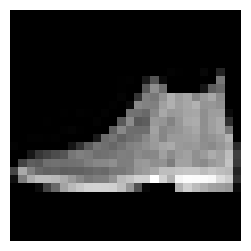

True label : Ankle boot
Prediction : Ankle boot
Confidence : 0.9967988729476929


In [22]:
sample_image = X_test[0]
sample_true_label = y_test[0]

sample_prob = model.predict(sample_image[None, ...], verbose=0)[0]
sample_pred = np.argmax(sample_prob)

plt.figure(figsize=(3, 3))
plt.imshow(sample_image, cmap="gray")
plt.axis("off")
plt.savefig(os.path.join(OUTPUT_DIR, "inference_1_anh.png"), bbox_inches="tight", dpi=140)
plt.show()

print("True label :", class_names[sample_true_label])
print("Prediction :", class_names[sample_pred])
print("Confidence :", float(sample_prob[sample_pred]))

### Hướng dẫn đọc kết quả

`sample_image[None, ...]` thêm chiều batch:

- trước: `(28, 28)`
- sau: `(1, 28, 28)`

### Phân tích thực tế

Framework Deep Learning thường yêu cầu input có batch dimension ngay cả khi chỉ dự đoán một ảnh.

## 20. Lưu và khôi phục mô hình

Sau khi huấn luyện xong, mô hình cần được lưu để:
- triển khai;
- tiếp tục huấn luyện;
- tái sử dụng sau này.

Keras cho phép lưu toàn bộ kiến trúc và trọng số vào file `.keras`.

In [23]:
final_model_path = os.path.join(OUTPUT_DIR, "fashion_mnist_mlp_final.keras")

model.save(final_model_path)

loaded_model = tf.keras.models.load_model(final_model_path)

loaded_loss, loaded_acc = loaded_model.evaluate(test_ds, verbose=0)

print("Loaded model test accuracy:", round(float(loaded_acc), 4))

loaded_prob = loaded_model.predict(X_test, verbose=0)
print("Sai lệch xác suất lớn nhất sau lưu/khôi phục:", float(np.max(np.abs(loaded_prob - y_prob))))
print("Số nhãn thay đổi sau lưu/khôi phục:", int(np.sum(np.argmax(loaded_prob, axis=1) != y_pred)))


Loaded model test accuracy: 0.8862
Sai lệch xác suất lớn nhất sau lưu/khôi phục: 0.0
Số nhãn thay đổi sau lưu/khôi phục: 0


### Hướng dẫn đọc kết quả

Nếu accuracy sau khi load gần như giống mô hình trước khi lưu, quá trình lưu/khôi phục đã thành công.

### Phân tích thực tế

Đây là bước nối từ training sang deployment. Trong dự án thật, model artifact cần được quản lý cùng:
- phiên bản dữ liệu;
- hyperparameter;
- code;
- metric.

# 21. Tổng kết workflow Deep Learning

Một workflow Deep Learning điển hình:

**Bước 1. Chuẩn bị dữ liệu**  
↓  
**Bước 2. Train / Validation / Test split**  
↓  
**Bước 3. Tiền xử lý và tạo batch**  
↓  
**Bước 4. Xây dựng kiến trúc mạng**  
↓  
**Bước 5. Compile: optimizer + loss + metric**  
↓  
**Bước 6. Train bằng mini-batch**  
↓  
**Bước 7. Theo dõi validation và callback**  
↓  
**Bước 8. Phân tích learning curves**  
↓  
**Bước 9. Đánh giá trên test set**  
↓  
**Bước 10. Error analysis**  
↓  
**Bước 11. Inference và lưu mô hình**

---

## So sánh nhanh với workflow Machine Learning cổ điển

| Machine Learning cổ điển | Deep Learning |
|---|---|
| Feature engineering thường rất quan trọng | Mô hình học representation từ dữ liệu |
| `fit(X_train, y_train)` thường là một bước tương đối gọn | Training gồm nhiều epoch và mini-batch |
| Ít cần quan sát quá trình tối ưu | Cần theo dõi loss/metric theo epoch |
| Model selection dựa nhiều vào CV | Validation set và learning curve rất quan trọng |
| Model thường nhỏ | Số parameter có thể rất lớn |
| Training nhanh | Training có thể tốn GPU và thời gian |

---

## Câu hỏi thảo luận

1. Vì sao MLP cần `Flatten` ảnh trước Dense layer?
2. Validation set khác test set ở điểm nào?
3. Một epoch là gì? Một batch là gì?
4. Khi nào training loss giảm nhưng validation loss tăng?
5. EarlyStopping giúp giải quyết vấn đề gì?
6. Vì sao không nên dùng test set để chọn hyperparameter?
7. Tại sao MLP chưa phải kiến trúc tối ưu cho ảnh?
8. Nếu tăng số neuron/layer, điều gì có thể xảy ra?
9. Nếu learning rate quá lớn, learning curve có thể có đặc điểm gì?
10. Bước tiếp theo để cải thiện mô hình cho ảnh là kiến trúc nào?

# 22. Bài tập mở rộng cho sinh viên

### Bài 1. Thay đổi kiến trúc
Thử các mô hình:
- 1 hidden layer;
- 2 hidden layers;
- 3 hidden layers.

So sánh:
- số parameter;
- thời gian train;
- validation accuracy;
- test accuracy.

### Bài 2. Thử learning rate
Huấn luyện với:
- `1e-2`
- `1e-3`
- `1e-4`

Nhận xét learning curve.

### Bài 3. Thử batch size
So sánh:
- 32
- 128
- 512

Nhận xét tốc độ và kết quả.

### Bài 4. Thêm Dropout
Thêm `Dropout(0.3)` giữa các Dense layer.  
Quan sát khoảng cách train/validation accuracy.

### Bài 5. Thêm L2 regularization
Dùng `kernel_regularizer=tf.keras.regularizers.l2(...)`.

### Bài 6. Phân tích lỗi
Tìm 20 mẫu mô hình dự đoán sai với confidence cao nhất.  
Phân tích vì sao chúng khó.
---

## Yêu cầu báo cáo ngắn

Sinh viên cần trả lời:

1. Kiến trúc mô hình đã sử dụng.
2. Optimizer, loss, learning rate, batch size.
3. Epoch tốt nhất.
4. Training/validation learning curves.
5. Test accuracy.
6. Hai cặp lớp bị nhầm nhiều nhất.
7. Nhận xét underfitting/overfitting.
8. Một thay đổi đã thử để cải thiện mô hình và kết quả.

## 23. Trả lời câu hỏi thảo luận

1. **Vì sao dùng Flatten?** Ảnh có 28 × 28 = 784 pixel. Flatten chuyển mỗi ảnh thành vector 784 phần tử để Dense kết nối với toàn bộ pixel theo kiến trúc MLP trong bài.
2. **Validation và test khác nhau ở đâu?** Validation theo dõi khả năng tổng quát hóa, chọn epoch và cấu hình. Test đánh giá mô hình sau khi cấu hình đã được xác định.
3. **Epoch và batch là gì?** Một batch là nhóm ảnh được xử lý trong một bước cập nhật. Một epoch là một lượt đi qua toàn bộ tập train. Với 50.000 ảnh và batch 64, mỗi epoch có 782 batch, trong đó batch cuối có 16 ảnh.
4. **Train loss giảm nhưng validation loss tăng khi nào?** Đây là dấu hiệu mô hình bắt đầu overfit, học ngày càng tốt dữ liệu train nhưng khả năng tổng quát hóa trên validation giảm.
5. **EarlyStopping giúp gì?** Dừng khi chỉ số validation thiếu cải thiện qua số epoch đã đặt. `restore_best_weights=True` khôi phục trọng số ở epoch có validation loss thấp nhất.
6. **Vì sao chọn hyperparameter bằng test gây vấn đề?** Việc lựa chọn sẽ phụ thuộc vào test, khiến kết quả test giảm tính khách quan khi đại diện cho dữ liệu mới. Các cấu hình trong bài được định trước và so sánh bằng validation.
7. **Vì sao MLP có hạn chế với ảnh?** Dense kết nối toàn bộ pixel và cần nhiều tham số. Sau Flatten, MLP khai thác cấu trúc không gian của ảnh kém hiệu quả hơn CNN như bài giảng đã nêu.
8. **Tăng neuron hoặc layer có thể dẫn đến gì?** Số tham số và chi phí tính toán thường tăng. Khả năng học có thể tăng, đồng thời nguy cơ overfitting cũng tăng. Cần đọc validation và learning curve để đánh giá.
9. **Learning rate quá lớn có biểu hiện gì?** Loss có thể dao động hoặc tăng do bước cập nhật lớn, khiến quá trình học khó ổn định.
10. **Kiến trúc tiếp theo cho ảnh là gì?** CNN, kiến trúc được bài giảng giới thiệu như hướng tiếp theo để khai thác cấu trúc không gian của ảnh.

## 24. Bài 1 — Thay đổi kiến trúc

Các cấu hình được đặt trước khi chạy thí nghiệm. Giữ seed 42, ReLU ở lớp ẩn, Softmax ở đầu ra, Adam, sparse cross-entropy, tối đa 40 epoch và callback giống bài giảng. Giữ validation/test batch bằng 64. Mỗi lần fit tạo mới mô hình, optimizer, callback và pipeline train. Mô hình gốc hai lớp ẩn được dùng lại ở các bảng có cùng cấu hình.

Thời gian fit đo bằng đồng hồ quanh `fit()`, gồm train, validation và checkpoint. Giây/epoch bằng thời gian fit chia số epoch thực chạy. Các phép đo này phụ thuộc môi trường. Epoch được chọn theo `val_loss` thấp nhất trong từng lần fit. Accuracy tại epoch đó được lấy từ history. Các bảng so sánh Dropout/L2 còn đánh giá train và validation bằng cùng trọng số đã khôi phục qua `evaluate()`.

Mỗi Dense có `số đầu vào × số neuron + số neuron` tham số. Một lớp ẩn dùng 256 neuron. Hai lớp dùng 256 → 128. Ba lớp dùng 256 → 128 → 64.

Đã chạy 1_lop_an, 12 epoch, 18.01 giây.
Đã chạy 3_lop_an, 12 epoch, 19.84 giây.


,Lớp ẩn,Tham số,Fit (s),Giây/epoch,Epoch chạy,Epoch tốt nhất,Val accuracy
0,256,203530,18.012489,1.501041,12,9,0.8840
1,256 → 128,235146,19.023545,1.585295,12,9,0.8891
2,256 → 128 → 64,242762,19.835026,1.652919,12,9,0.8890


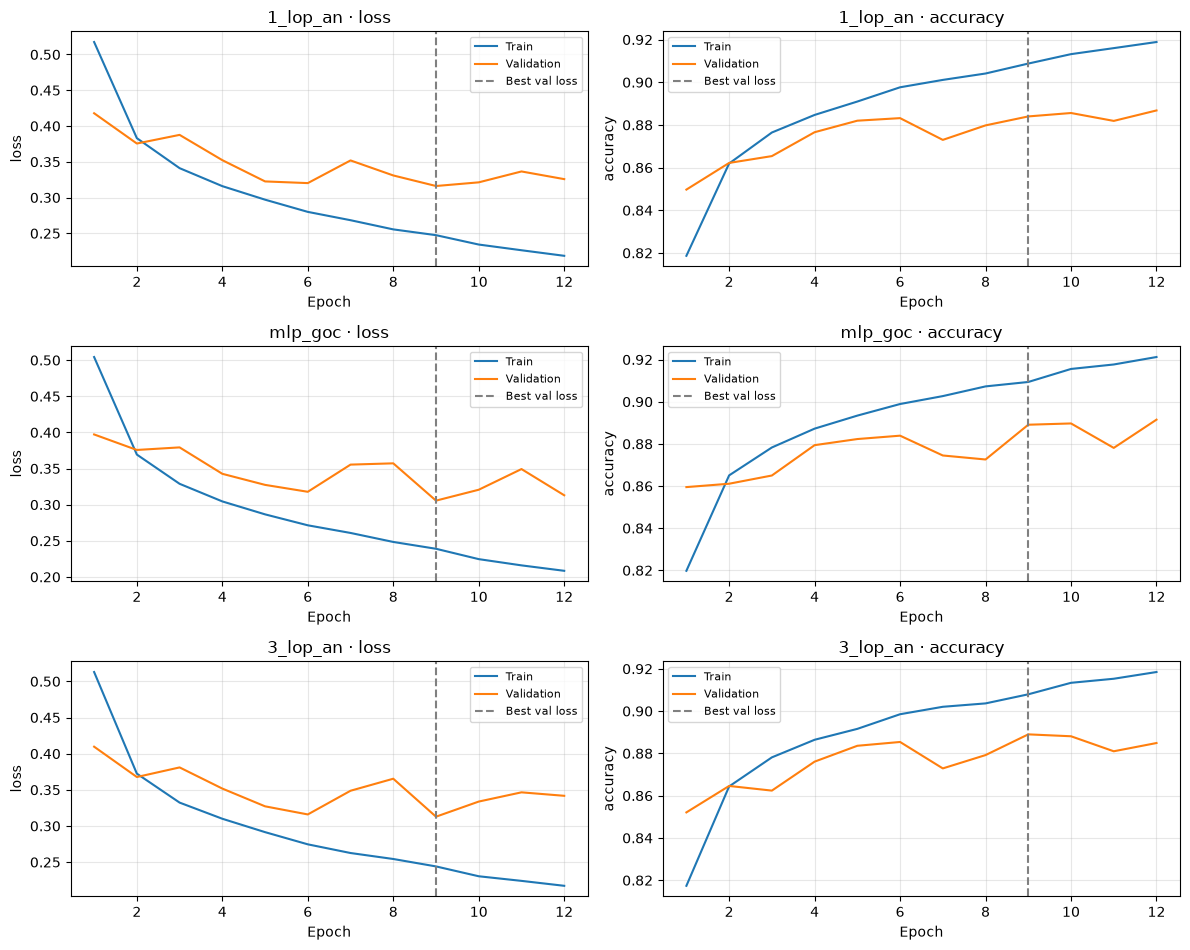

In [24]:
runs = {}
histories = {}

def record_run(name, network, curve, fit_seconds, hidden=(256, 128),
               learning_rate=1e-3, batch_size=64, dropout=0.0, l2_strength=0.0):
    frame = pd.DataFrame(curve)
    frame.index = np.arange(1, len(frame) + 1)
    frame.index.name = "Epoch"
    best_epoch = int(frame["val_loss"].idxmin())
    train_loss, train_accuracy = network.evaluate(train_eval_ds, verbose=0)
    val_loss, val_accuracy = network.evaluate(val_ds, verbose=0)
    runs[name] = {
        "Cấu hình": name, "Lớp ẩn": " → ".join(str(n) for n in hidden),
        "Tham số": network.count_params(), "Learning rate": learning_rate,
        "Batch size": batch_size, "Dropout": dropout, "L2": l2_strength,
        "Epoch chạy": len(frame), "Epoch tốt nhất": best_epoch,
        "Fit (s)": fit_seconds, "Giây/epoch": fit_seconds / len(frame),
        "Batch/epoch": (len(X_train) + batch_size - 1) // batch_size,
        "Train acc (fit)": float(frame.loc[best_epoch, "accuracy"]),
        "Val acc (fit)": float(frame.loc[best_epoch, "val_accuracy"]),
        "Val loss tốt nhất": float(frame.loc[best_epoch, "val_loss"]),
        "Train accuracy": float(train_accuracy), "Val accuracy": float(val_accuracy),
        "Train loss": float(train_loss), "Val loss": float(val_loss),
        "Chênh train − val (đpt)": 100 * (train_accuracy - val_accuracy),
    }
    histories[name] = frame
    frame.to_csv(os.path.join(OUTPUT_DIR, f"history_{name}.csv"), encoding="utf-8-sig")

def train_variant(name, hidden=(256, 128), learning_rate=1e-3, batch_size=64,
                  dropout=0.0, l2_strength=0.0):
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)
    dataset = make_train_dataset(batch_size)
    layers = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten()]
    regularizer = tf.keras.regularizers.l2(l2_strength) if l2_strength else None
    for layer_index, units in enumerate(hidden):
        layers.append(tf.keras.layers.Dense(
            units, activation="relu", kernel_regularizer=regularizer
        ))
        if dropout and layer_index < len(hidden) - 1:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    network = tf.keras.Sequential(layers)
    network.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"],
    )
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=os.path.join(OUTPUT_DIR, f"best_{name}.keras"),
            monitor="val_loss", save_best_only=True,
        ),
    ]
    start = perf_counter()
    fitted = network.fit(dataset, validation_data=val_ds, epochs=EPOCHS,
                         callbacks=callbacks, verbose=0, shuffle=False)
    seconds = perf_counter() - start
    record_run(name, network, fitted.history, seconds, hidden, learning_rate,
               batch_size, dropout, l2_strength)
    print(f"Đã chạy {name}, {len(fitted.history['loss'])} epoch, {seconds:.2f} giây.")

def show_run_table(names, columns, filename):
    table = pd.DataFrame([runs[name] for name in names])
    table.to_csv(os.path.join(OUTPUT_DIR, filename + ".csv"), index=False, encoding="utf-8-sig")
    display(table[columns].round(6))
    return table

def plot_learning_curves(names, filename):
    fig, axes = plt.subplots(len(names), 2, figsize=(12, 3.2 * len(names)), squeeze=False)
    for row, name in enumerate(names):
        frame = histories[name]
        for col, metric in enumerate(["loss", "accuracy"]):
            ax = axes[row, col]
            ax.plot(frame.index, frame[metric], label="Train")
            ax.plot(frame.index, frame["val_" + metric], label="Validation")
            ax.axvline(runs[name]["Epoch tốt nhất"], color="gray", linestyle="--", label="Best val loss")
            ax.set_title(name + " · " + metric)
            ax.set_xlabel("Epoch")
            ax.set_ylabel(metric)
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename + ".png"), bbox_inches="tight", dpi=140)
    plt.show()

record_run("mlp_goc", model, history.history, baseline_fit_seconds)
runs["mlp_goc"]["Test accuracy"] = float(test_accuracy)
runs["mlp_goc"]["Test loss"] = float(test_loss)
train_variant("1_lop_an", hidden=(256,))
train_variant("3_lop_an", hidden=(256, 128, 64))
architecture_names = ["1_lop_an", "mlp_goc", "3_lop_an"]
architecture_columns = ["Lớp ẩn", "Tham số", "Fit (s)", "Giây/epoch", "Epoch chạy",
                        "Epoch tốt nhất", "Val accuracy"]
show_run_table(architecture_names, architecture_columns, "bai1_kien_truc_validation")
plot_learning_curves(architecture_names, "bai1_learning_curves")

In [25]:
architecture_table = pd.DataFrame([runs[name] for name in architecture_names])
best_architecture = architecture_table.loc[architecture_table["Val accuracy"].idxmax()]
fastest = architecture_table.loc[architecture_table["Giây/epoch"].idxmin()]
print(f"Số tham số lần lượt là {runs['1_lop_an']['Tham số']:,}, "
      f"{runs['mlp_goc']['Tham số']:,} và {runs['3_lop_an']['Tham số']:,}.")
print(f"Validation accuracy cao nhất là {best_architecture['Val accuracy']:.2%} "
      f"ở kiến trúc {best_architecture['Lớp ẩn']}.")
print(f"Thời gian mỗi epoch ngắn nhất ở kiến trúc {fastest['Lớp ẩn']}, "
      f"{fastest['Giây/epoch']:.2f} giây. Tổng thời gian còn phụ thuộc số epoch thực chạy.")

Số tham số lần lượt là 203,530, 235,146 và 242,762.
Validation accuracy cao nhất là 88.91% ở kiến trúc 256 → 128.
Thời gian mỗi epoch ngắn nhất ở kiến trúc 256, 1.50 giây. Tổng thời gian còn phụ thuộc số epoch thực chạy.


## 25. Bài 2 — Thử learning rate

Giữ hai lớp ẩn 256 → 128 và batch 64. Thử `1e-2`, `1e-3`, `1e-4`. Bảng thống kê loss, accuracy, epoch được chọn và tốc độ. Biểu đồ có cả train/validation loss và train/validation accuracy cho từng learning rate. Test accuracy được bổ sung ở mục 30 sau khi các thí nghiệm đã hoàn tất.

Đã chạy lr_1e_2, 9 epoch, 13.79 giây.
Đã chạy lr_1e_4, 11 epoch, 16.55 giây.


,Learning rate,Epoch chạy,Epoch tốt nhất,Fit (s),Val loss tốt nhất,Train acc (fit),Val acc (fit)
0,0.0100,9,6,13.790898,0.376212,0.87108,0.8629
1,0.0010,12,9,19.023545,0.305609,0.90938,0.8891
2,0.0001,11,8,16.545843,0.343510,0.88740,0.8767


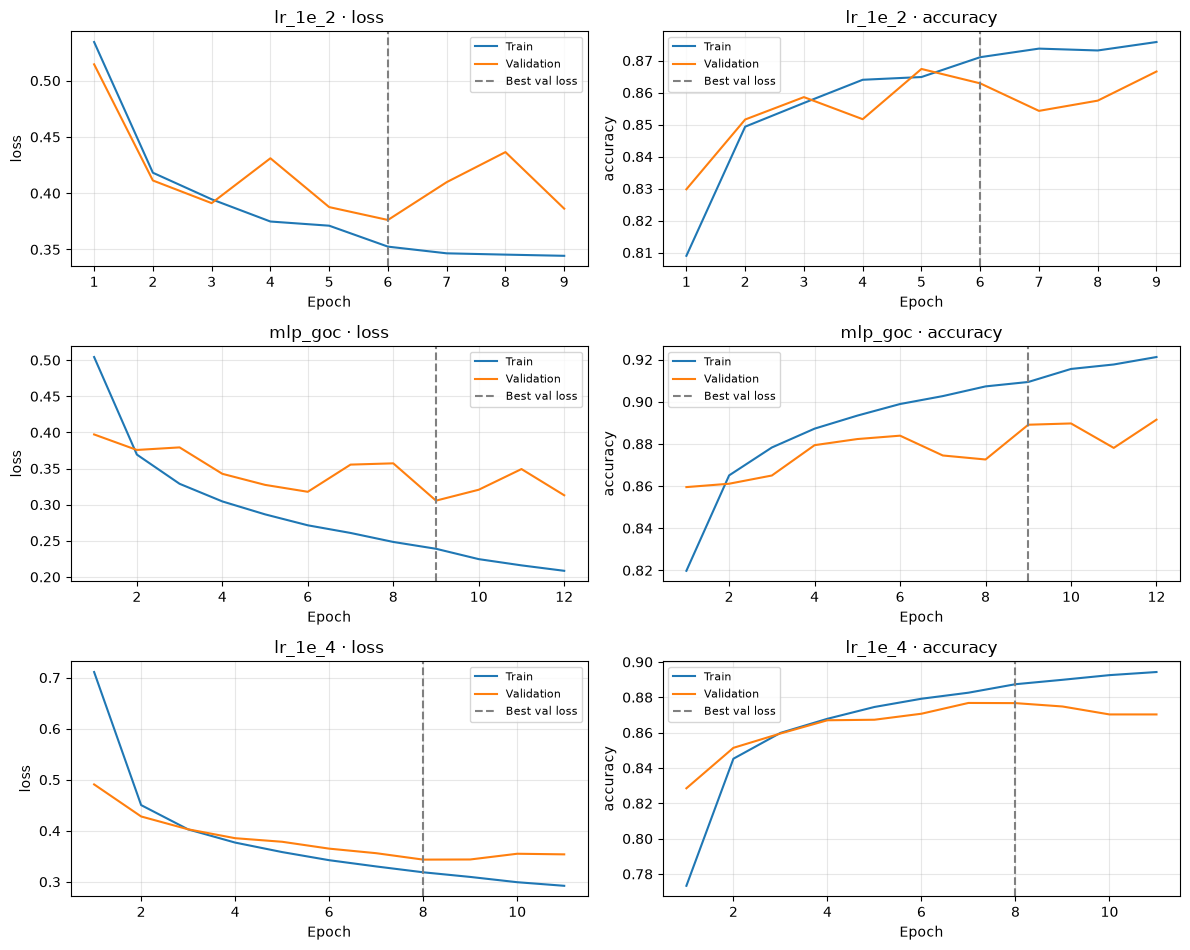

LR 0.01, val loss đầu 0.5145, thấp nhất 0.3762, val loss tăng 3/8 lần chuyển epoch.
LR 0.001, val loss đầu 0.3972, thấp nhất 0.3056, val loss tăng 5/11 lần chuyển epoch.
LR 0.0001, val loss đầu 0.4909, thấp nhất 0.3435, val loss tăng 2/10 lần chuyển epoch.
Trong lần thử này, learning rate 0.001 cho validation loss thấp nhất.


In [26]:
train_variant("lr_1e_2", learning_rate=1e-2)
train_variant("lr_1e_4", learning_rate=1e-4)
lr_names = ["lr_1e_2", "mlp_goc", "lr_1e_4"]
lr_columns = ["Learning rate", "Epoch chạy", "Epoch tốt nhất", "Fit (s)",
              "Val loss tốt nhất", "Train acc (fit)", "Val acc (fit)"]
show_run_table(lr_names, lr_columns, "bai2_learning_rate_validation")
plot_learning_curves(lr_names, "bai2_learning_curves")
for name in lr_names:
    frame = histories[name]
    increases = int((frame["val_loss"].diff().dropna() > 0).sum())
    print(f"LR {runs[name]['Learning rate']:g}, val loss đầu {frame.iloc[0]['val_loss']:.4f}, "
          f"thấp nhất {frame['val_loss'].min():.4f}, "
          f"val loss tăng {increases}/{len(frame) - 1} lần chuyển epoch.")
best_lr = min(lr_names, key=lambda name: runs[name]["Val loss tốt nhất"])
print(f"Trong lần thử này, learning rate {runs[best_lr]['Learning rate']:g} "
      "cho validation loss thấp nhất.")

## 26. Bài 3 — Thử batch size

Giữ kiến trúc hai lớp ẩn và learning rate `1e-3`. Chỉ đổi batch size train thành 32, 128, 512. Số batch mỗi epoch tính bằng số ảnh train chia batch size rồi làm tròn lên. Đối chiếu tốc độ mỗi epoch và tổng thời gian với số epoch thực chạy.

Đã chạy batch_32, 12 epoch, 27.18 giây.
Đã chạy batch_128, 17 epoch, 15.22 giây.
Đã chạy batch_512, 12 epoch, 7.10 giây.


,Batch size,Batch/epoch,Fit (s),Giây/epoch,Epoch chạy,Epoch tốt nhất,Val accuracy
0,32,1563,27.180385,2.265032,12,9,0.8891
1,128,391,15.221568,0.895386,17,14,0.8918
2,512,98,7.098666,0.591555,12,9,0.8838


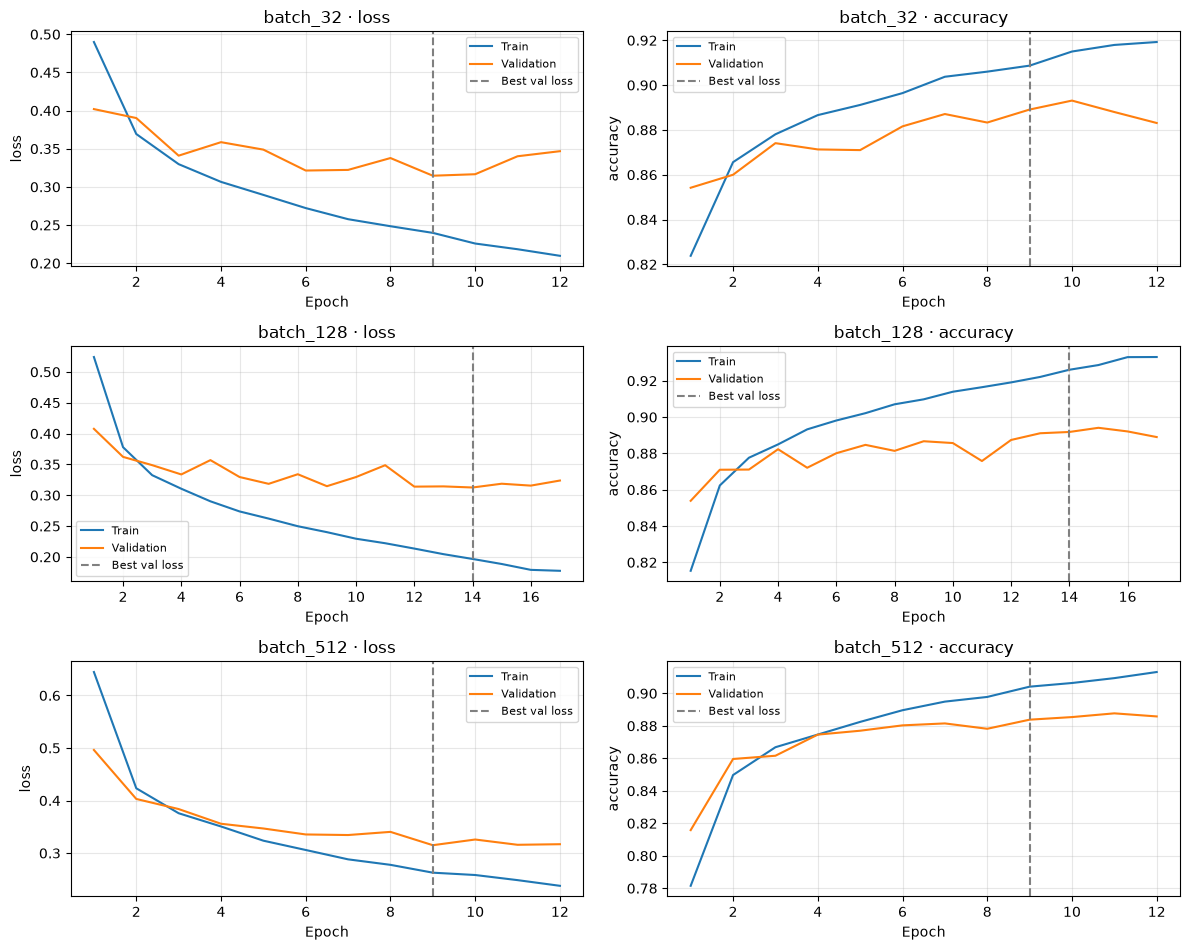

Batch 512 có giây/epoch thấp nhất (0.59 giây).
Batch 128 có validation accuracy cao nhất (89.18%) trong ba mức thử.


In [27]:
batch_names = []
for batch_size in [32, 128, 512]:
    name = f"batch_{batch_size}"
    train_variant(name, batch_size=batch_size)
    batch_names.append(name)
batch_columns = ["Batch size", "Batch/epoch", "Fit (s)", "Giây/epoch", "Epoch chạy",
                 "Epoch tốt nhất", "Val accuracy"]
batch_table = show_run_table(batch_names, batch_columns, "bai3_batch_size_validation")
plot_learning_curves(batch_names, "bai3_learning_curves")
fastest_batch = batch_table.loc[batch_table["Giây/epoch"].idxmin()]
best_batch = batch_table.loc[batch_table["Val accuracy"].idxmax()]
print(f"Batch {int(fastest_batch['Batch size'])} có giây/epoch thấp nhất "
      f"({fastest_batch['Giây/epoch']:.2f} giây).")
print(f"Batch {int(best_batch['Batch size'])} có validation accuracy cao nhất "
      f"({best_batch['Val accuracy']:.2%}) trong ba mức thử.")

## 27. Bài 4 — Thêm Dropout

Kiến trúc thử là Flatten → Dense(256, ReLU) → Dropout(0.3) → Dense(128, ReLU) → Dense(10, Softmax). Dropout đặt giữa hai Dense ẩn. Giữ learning rate và batch size của mô hình gốc.

Đường train accuracy trong `fit()` được ghi lúc trọng số đang cập nhật và Dropout đang hoạt động. Bảng còn có train/validation accuracy tính qua `evaluate()` tại cùng trọng số tốt nhất, trong chế độ suy luận. Chênh lệch trong bảng bằng `(train accuracy − validation accuracy) × 100`, đơn vị điểm phần trăm.

Đã chạy dropout_03, 20 epoch, 33.68 giây.


,Cấu hình,Epoch tốt nhất,Train acc (fit),Val acc (fit),Train accuracy,Val accuracy,Chênh train − val (đpt)
0,mlp_goc,9,0.90938,0.8891,0.92298,0.8891,3.388
1,dropout_03,17,0.90408,0.8907,0.91800,0.8907,2.730


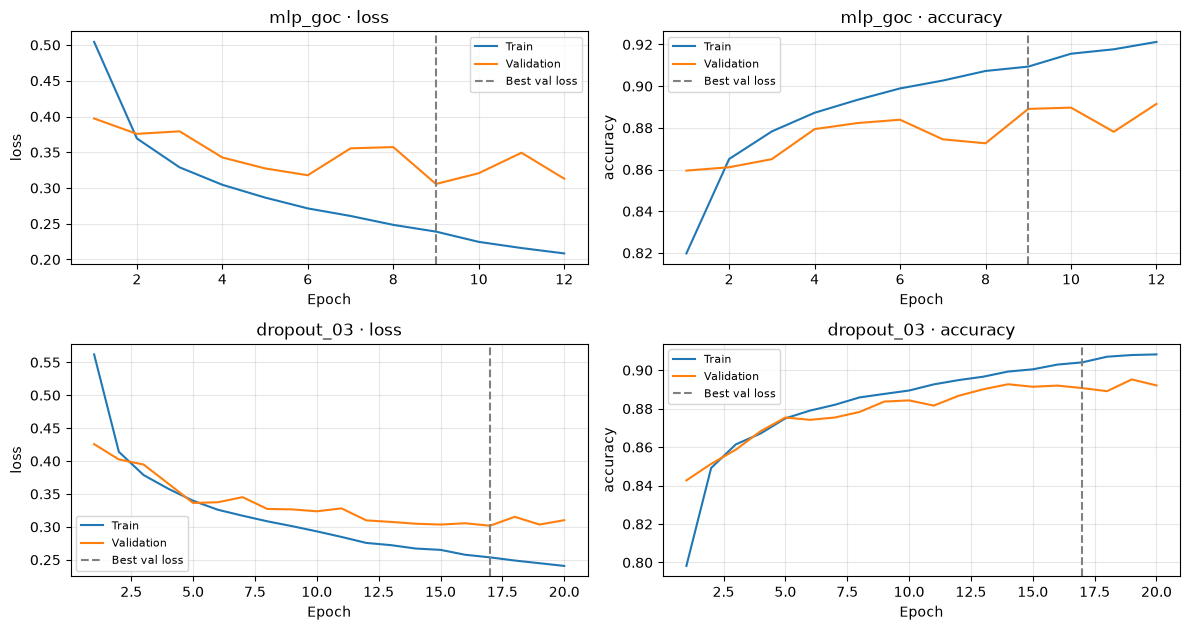

Dropout so với mô hình gốc, chênh train − val thay đổi -0.66 đpt, validation accuracy thay đổi +0.16 đpt.


In [28]:
train_variant("dropout_03", dropout=0.3)
regularization_columns = ["Cấu hình", "Epoch tốt nhất", "Train acc (fit)", "Val acc (fit)",
                          "Train accuracy", "Val accuracy", "Chênh train − val (đpt)"]
show_run_table(["mlp_goc", "dropout_03"], regularization_columns, "bai4_dropout_validation")
plot_learning_curves(["mlp_goc", "dropout_03"], "bai4_dropout_learning_curves")
gap_change = runs["dropout_03"]["Chênh train − val (đpt)"] - runs["mlp_goc"]["Chênh train − val (đpt)"]
val_change = 100 * (runs["dropout_03"]["Val accuracy"] - runs["mlp_goc"]["Val accuracy"])
print(f"Dropout so với mô hình gốc, chênh train − val thay đổi {gap_change:+.2f} đpt, "
      f"validation accuracy thay đổi {val_change:+.2f} đpt.")

## 28. Bài 5 — Thêm L2 regularization

Đặt `kernel_regularizer=tf.keras.regularizers.l2(1e-4)` ở cả hai Dense ẩn, giữ nguyên lớp đầu ra và các thiết lập khác. L2 cộng phần phạt trọng số vào loss. Bảng so sánh accuracy và chênh lệch train/validation. Đồ thị loss của mỗi mô hình dùng để quan sát quá trình học của chính cấu hình đó.

Đã chạy l2_1e_4, 12 epoch, 27.05 giây.


,Cấu hình,Epoch tốt nhất,Train acc (fit),Val acc (fit),Train accuracy,Val accuracy,Chênh train − val (đpt)
0,mlp_goc,9,0.90938,0.8891,0.92298,0.8891,3.388
1,l2_1e_4,9,0.90078,0.8891,0.91368,0.8891,2.458


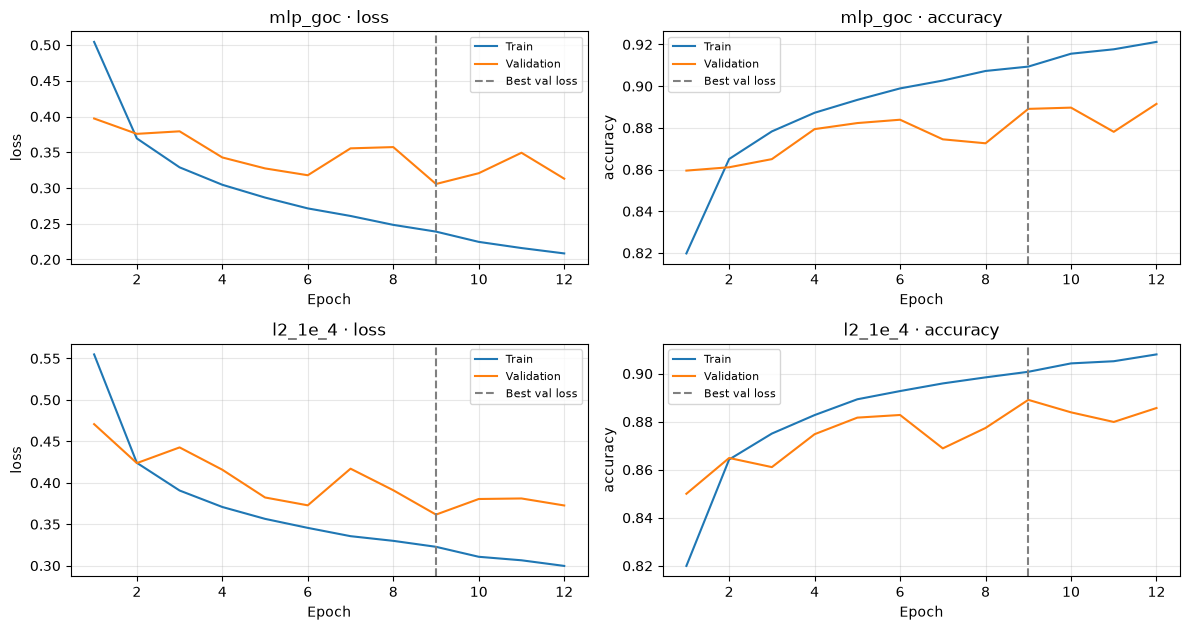

L2 so với mô hình gốc, chênh train − val thay đổi -0.93 đpt, validation accuracy thay đổi +0.00 đpt.


In [29]:
train_variant("l2_1e_4", l2_strength=1e-4)
show_run_table(["mlp_goc", "l2_1e_4"], regularization_columns, "bai5_l2_validation")
plot_learning_curves(["mlp_goc", "l2_1e_4"], "bai5_l2_learning_curves")
gap_change = runs["l2_1e_4"]["Chênh train − val (đpt)"] - runs["mlp_goc"]["Chênh train − val (đpt)"]
val_change = 100 * (runs["l2_1e_4"]["Val accuracy"] - runs["mlp_goc"]["Val accuracy"])
print(f"L2 so với mô hình gốc, chênh train − val thay đổi {gap_change:+.2f} đpt, "
      f"validation accuracy thay đổi {val_change:+.2f} đpt.")

## 29. Bài 6 — Phân tích 20 lỗi có confidence cao nhất

Dùng MLP gốc để phân tích. Lọc ảnh sai trước, lấy xác suất của lớp dự đoán, rồi sắp xếp giảm dần. Chỉ số ảnh bắt đầu từ 0 và trùng dòng trong file dự đoán test. Bảng cho biết nhãn thật, nhãn dự đoán, confidence của nhãn dự đoán và xác suất mô hình gán cho nhãn thật. Mỗi ảnh có một dòng phân tích quan sát phía dưới hình.

,Chỉ số ảnh,Nhãn thật,Dự đoán,Confidence,Xác suất nhãn thật
0,4394,Dress,Bag,0.999876,0.000116
1,2856,Shirt,T-shirt/top,0.999813,0.000168
2,5235,Sandal,Bag,0.999731,0.000057
3,5155,Shirt,Pullover,0.999670,0.000282
4,3531,T-shirt/top,Dress,0.999605,0.000039
5,5946,Ankle boot,Sandal,0.999539,0.000461
6,12,Sneaker,Sandal,0.999463,0.000503
7,787,Trouser,Dress,0.999413,0.000139
8,324,Coat,Shirt,0.998894,0.000994
9,979,Dress,T-shirt/top,0.998508,0.000142


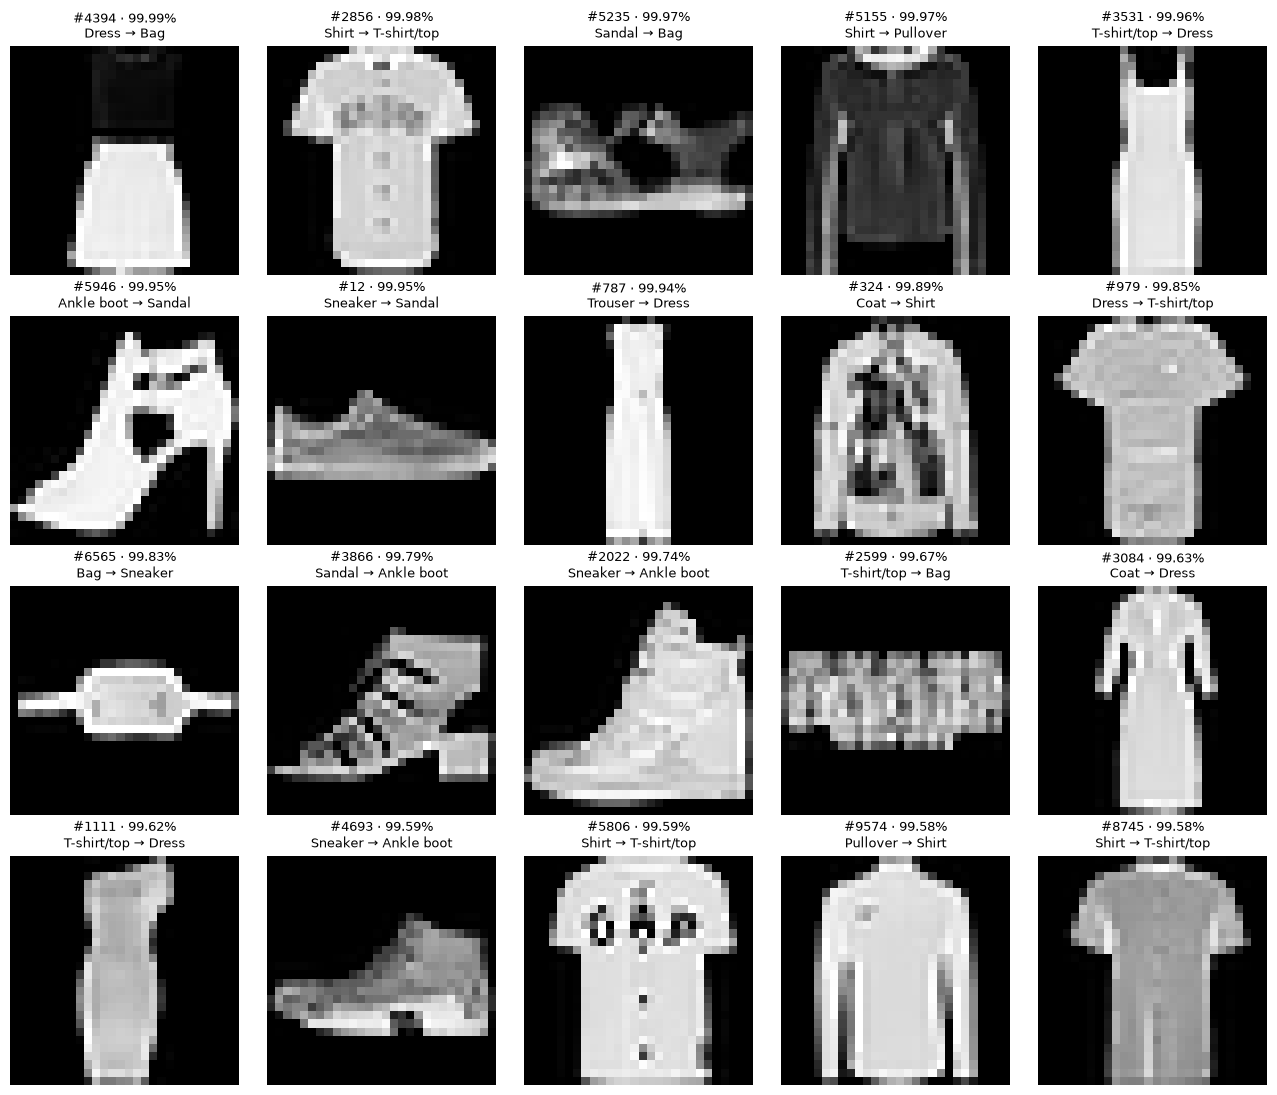

,Nhãn thật,Dự đoán,Số ảnh trong 20 lỗi
0,Shirt,T-shirt/top,3
1,Sneaker,Ankle boot,2
2,T-shirt/top,Dress,2
3,Ankle boot,Sandal,1
4,Dress,Bag,1
5,Bag,Sneaker,1
6,Coat,Dress,1
7,Coat,Shirt,1
8,Sandal,Ankle boot,1
9,Pullover,Shirt,1


In [30]:
wrong_confidence = y_prob[wrong_indices, y_pred[wrong_indices]]
order = np.argsort(-wrong_confidence, kind="stable")[:20]
top_wrong = wrong_indices[order]
wrong_examples = pd.DataFrame({
    "Chỉ số ảnh": top_wrong,
    "Nhãn thật": [class_names[i] for i in y_test[top_wrong]],
    "Dự đoán": [class_names[i] for i in y_pred[top_wrong]],
    "Confidence": y_prob[top_wrong, y_pred[top_wrong]],
    "Xác suất nhãn thật": y_prob[top_wrong, y_test[top_wrong]],
})
display(wrong_examples.round(6))
wrong_examples.to_csv(os.path.join(OUTPUT_DIR, "bai6_top20_loi.csv"), index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(4, 5, figsize=(13, 11))
for idx, ax in zip(top_wrong, axes.ravel()):
    truth, guess = y_test[idx], y_pred[idx]
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(f"#{idx} · {y_prob[idx, guess]:.2%}\n"
                 f"{class_names[truth]} → {class_names[guess]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "bai6_top20_loi.png"), bbox_inches="tight", dpi=140)
plt.show()
wrong_groups = wrong_examples.groupby(["Nhãn thật", "Dự đoán"]).size().sort_values(ascending=False)
display(wrong_groups.rename("Số ảnh trong 20 lỗi").reset_index())

In [31]:
observed_errors = {4394: 'Phần thân trên của váy rất tối, chỉ phần dưới sáng hiện rõ thành khối gần hình túi, khiến toàn bộ dáng váy khó nhận ra.', 2856: 'Áo có tay ngắn và thân giống áo thun. Hàng chi tiết giữa thân rất nhỏ ở ảnh 28 × 28 nên đặc điểm phân biệt Shirt khó thấy.', 5235: 'Quai sandal tạo nhiều khoảng trống và các nét vòng phía trên, có thể giống quai túi khi các chi tiết đế bị thu nhỏ.', 5155: 'Áo tối màu, tay dài và thân liền. Đường mở hoặc khuy phía trước khó thấy nên hình dáng gần áo Pullover.', 3531: 'Áo có thân rất dài và tay gần như không hiện rõ, tạo dáng thẳng giống một chiếc váy.', 5946: 'Bốt có gót cao cùng các khoảng hở lớn ở thân trên. Các khoảng hở tạo hình gần với sandal có nhiều quai.', 12: 'Giày thể thao có dáng thấp, màu tối và chi tiết dây mờ. Đường viền đế và thân giày chiếm phần nổi bật của ảnh.', 787: 'Quần sáng màu và hai ống gần nhau. Khe giữa hai ống rất mảnh nên đường viền tổng thể gần một chiếc váy dài.', 324: 'Áo khoác có họa tiết tương phản mạnh, cổ và tay giống áo sơ mi. Họa tiết làm đường cài hoặc mở áo khó tách biệt.', 979: 'Váy có tay ngắn và thân ít xòe trong ảnh, làm dáng tổng thể gần áo T-shirt/top.', 6565: 'Túi có thân nằm ngang, dây kéo dài sang hai phía. Khối sáng và chiều ngang có thể bị liên hệ với dáng giày.', 3866: 'Sandal có quai phủ cao tới cổ chân và gót lớn, tạo đường viền gần một chiếc bốt cổ ngắn.', 2022: 'Giày Sneaker có cổ cao, phần cổ và thân sáng nối liền, làm đường viền tổng thể giống Ankle boot.', 2599: 'Ảnh chủ yếu hiện một dải họa tiết nằm ngang, phần cổ và tay áo khó nhận ra, nên dáng trang phục dễ bị nhầm với túi.', 3084: 'Áo khoác có thân dài và hơi xòe. Đường mở giữa áo chỉ là nét hẹp, khiến phần thân dễ giống váy.', 1111: 'Áo có thân dài, dáng hẹp và tay rất nhỏ trong ảnh. Tỷ lệ chiều dài làm dáng tổng thể gần váy.', 4693: 'Sneaker có phần gót và cổ nhô cao, còn dây và cấu trúc mặt giày không rõ, nên đường viền gần bốt.', 5806: 'Áo Shirt có tay ngắn và chữ in lớn trên ngực, giống áo thun. Chi tiết hàng khuy nhỏ khó quan sát ở độ phân giải này.', 9574: 'Pullover sáng màu có vùng cổ và vài chi tiết nhỏ ở ngực dễ giống cổ hoặc khuy áo Shirt.', 8745: 'Áo Shirt có tay ngắn và bề mặt thân khá trơn. Các chi tiết giúp nhận ra cổ hay hàng khuy mờ nên giống T-shirt/top.'}
image_analysis = wrong_examples[["Chỉ số ảnh", "Nhãn thật", "Dự đoán"]].copy()
image_analysis["Quan sát và lý do có thể gây nhầm"] = [
    observed_errors.get(int(index), "Quan sát đường viền, độ dài thân và chi tiết ở độ phân giải 28 × 28.")
    for index in image_analysis["Chỉ số ảnh"]
]
display(image_analysis)
image_analysis.to_csv(os.path.join(OUTPUT_DIR, "bai6_phan_tich_20_anh.csv"), index=False, encoding="utf-8-sig")

,Chỉ số ảnh,Nhãn thật,Dự đoán,Quan sát và lý do có thể gây nhầm
0,4394,Dress,Bag,"Phần thân trên của váy rất tối, chỉ phần dưới sáng hiện rõ thành khối gần hình túi, khiến toàn bộ dáng váy khó nhận ra."
1,2856,Shirt,T-shirt/top,Áo có tay ngắn và thân giống áo thun. Hàng chi tiết giữa thân rất nhỏ ở ảnh 28 × 28 nên đặc điểm phân biệt Shirt khó thấy.
2,5235,Sandal,Bag,"Quai sandal tạo nhiều khoảng trống và các nét vòng phía trên, có thể giống quai túi khi các chi tiết đế bị thu nhỏ."
3,5155,Shirt,Pullover,"Áo tối màu, tay dài và thân liền. Đường mở hoặc khuy phía trước khó thấy nên hình dáng gần áo Pullover."
4,3531,T-shirt/top,Dress,"Áo có thân rất dài và tay gần như không hiện rõ, tạo dáng thẳng giống một chiếc váy."
5,5946,Ankle boot,Sandal,Bốt có gót cao cùng các khoảng hở lớn ở thân trên. Các khoảng hở tạo hình gần với sandal có nhiều quai.
6,12,Sneaker,Sandal,"Giày thể thao có dáng thấp, màu tối và chi tiết dây mờ. Đường viền đế và thân giày chiếm phần nổi bật của ảnh."
7,787,Trouser,Dress,Quần sáng màu và hai ống gần nhau. Khe giữa hai ống rất mảnh nên đường viền tổng thể gần một chiếc váy dài.
8,324,Coat,Shirt,"Áo khoác có họa tiết tương phản mạnh, cổ và tay giống áo sơ mi. Họa tiết làm đường cài hoặc mở áo khó tách biệt."
9,979,Dress,T-shirt/top,"Váy có tay ngắn và thân ít xòe trong ảnh, làm dáng tổng thể gần áo T-shirt/top."


Confidence là xác suất Softmax của lớp được dự đoán. Trong các ảnh ở trên, confidence cao vẫn đi kèm nhãn sai. Các lý do ghi trong bảng là nhận xét dựa trên ảnh và dự đoán. Ảnh 28 × 28 có ít chi tiết, một số lớp có hình dáng gần nhau, và MLP dùng Flatten để chuyển ảnh thành vector nên khả năng khai thác quan hệ không gian còn hạn chế như bài giảng đã nêu.

## 30. Báo cáo ngắn và tổng hợp kết quả

Các cấu hình đã hoàn tất huấn luyện ở mục 24–28. Bảng này bổ sung test accuracy sau khi trọng số của mỗi cấu hình đã được chọn bằng validation loss. Mô hình gốc là cấu hình được dùng xuyên suốt cho confusion matrix, classification report, inference và phân tích lỗi. Trong các bảng, accuracy dùng thang 0–1, còn chênh lệch accuracy dùng điểm phần trăm.

In [32]:
for name in runs:
    if name == "mlp_goc":
        continue
    restored = tf.keras.models.load_model(os.path.join(OUTPUT_DIR, f"best_{name}.keras"))
    loss, accuracy = restored.evaluate(test_ds, verbose=0)
    runs[name]["Test loss"] = float(loss)
    runs[name]["Test accuracy"] = float(accuracy)

all_results = pd.DataFrame(runs.values())
all_results.to_csv(os.path.join(OUTPUT_DIR, "tong_hop_10_cau_hinh.csv"), index=False, encoding="utf-8-sig")
display(all_results[["Cấu hình", "Lớp ẩn", "Learning rate", "Batch size", "Dropout", "L2", "Tham số"]])
display(all_results[["Cấu hình", "Epoch tốt nhất", "Epoch chạy", "Fit (s)", "Giây/epoch",
                     "Val accuracy", "Test accuracy"]].round(6))
final_columns = ["Cấu hình", "Tham số", "Epoch tốt nhất", "Fit (s)", "Val accuracy", "Test accuracy"]
display(Markdown("**Bài 1 — Kết quả kiến trúc, gồm test accuracy**"))
show_run_table(architecture_names, final_columns, "bai1_kien_truc_day_du")
display(Markdown("**Bài 2 — Kết quả learning rate, gồm test accuracy**"))
show_run_table(lr_names, ["Learning rate", "Val loss tốt nhất", "Epoch tốt nhất", "Val accuracy", "Test accuracy"],
               "bai2_learning_rate_day_du")
display(Markdown("**Bài 3 — Kết quả batch size, gồm test accuracy**"))
show_run_table(batch_names, ["Batch size", "Batch/epoch", "Fit (s)", "Giây/epoch", "Val accuracy", "Test accuracy"],
               "bai3_batch_size_day_du")
display(Markdown("**Bài 4–5 — Kết quả regularization, gồm test accuracy**"))
regularization_table = show_run_table(
    ["mlp_goc", "dropout_03", "l2_1e_4"],
    ["Cấu hình", "Epoch tốt nhất", "Train accuracy", "Val accuracy", "Chênh train − val (đpt)", "Test accuracy"],
    "bai4_bai5_regularization_day_du",
)

,Cấu hình,Lớp ẩn,Learning rate,Batch size,Dropout,L2,Tham số
0,mlp_goc,256 → 128,0.0010,64,0.0,0.0000,235146
1,1_lop_an,256,0.0010,64,0.0,0.0000,203530
2,3_lop_an,256 → 128 → 64,0.0010,64,0.0,0.0000,242762
3,lr_1e_2,256 → 128,0.0100,64,0.0,0.0000,235146
4,lr_1e_4,256 → 128,0.0001,64,0.0,0.0000,235146
5,batch_32,256 → 128,0.0010,32,0.0,0.0000,235146
6,batch_128,256 → 128,0.0010,128,0.0,0.0000,235146
7,batch_512,256 → 128,0.0010,512,0.0,0.0000,235146
8,dropout_03,256 → 128,0.0010,64,0.3,0.0000,235146
9,l2_1e_4,256 → 128,0.0010,64,0.0,0.0001,235146


,Cấu hình,Epoch tốt nhất,Epoch chạy,Fit (s),Giây/epoch,Val accuracy,Test accuracy
0,mlp_goc,9,12,19.023545,1.585295,0.8891,0.8862
1,1_lop_an,9,12,18.012489,1.501041,0.8840,0.8794
2,3_lop_an,9,12,19.835026,1.652919,0.8890,0.8840
3,lr_1e_2,6,9,13.790898,1.532322,0.8629,0.8549
4,lr_1e_4,8,11,16.545843,1.504168,0.8767,0.8708
5,batch_32,9,12,27.180385,2.265032,0.8891,0.8818
6,batch_128,14,17,15.221568,0.895386,0.8918,0.8845
7,batch_512,9,12,7.098666,0.591555,0.8838,0.8777
8,dropout_03,17,20,33.681414,1.684071,0.8907,0.8828
9,l2_1e_4,9,12,27.051829,2.254319,0.8891,0.8836


**Bài 1 — Kết quả kiến trúc, gồm test accuracy**

,Cấu hình,Tham số,Epoch tốt nhất,Fit (s),Val accuracy,Test accuracy
0,1_lop_an,203530,9,18.012489,0.8840,0.8794
1,mlp_goc,235146,9,19.023545,0.8891,0.8862
2,3_lop_an,242762,9,19.835026,0.8890,0.8840


**Bài 2 — Kết quả learning rate, gồm test accuracy**

,Learning rate,Val loss tốt nhất,Epoch tốt nhất,Val accuracy,Test accuracy
0,0.0100,0.376212,6,0.8629,0.8549
1,0.0010,0.305609,9,0.8891,0.8862
2,0.0001,0.343510,8,0.8767,0.8708


**Bài 3 — Kết quả batch size, gồm test accuracy**

,Batch size,Batch/epoch,Fit (s),Giây/epoch,Val accuracy,Test accuracy
0,32,1563,27.180385,2.265032,0.8891,0.8818
1,128,391,15.221568,0.895386,0.8918,0.8845
2,512,98,7.098666,0.591555,0.8838,0.8777


**Bài 4–5 — Kết quả regularization, gồm test accuracy**

,Cấu hình,Epoch tốt nhất,Train accuracy,Val accuracy,Chênh train − val (đpt),Test accuracy
0,mlp_goc,9,0.92298,0.8891,3.388,0.8862
1,dropout_03,17,0.91800,0.8907,2.730,0.8828
2,l2_1e_4,9,0.91368,0.8891,2.458,0.8836


In [33]:
class_a, class_b = np.triu_indices(len(class_names), k=1)
pair_counts = cm[class_a, class_b] + cm[class_b, class_a]
top_pair_indices = np.argsort(-pair_counts, kind="stable")[:2]
top_pairs = pd.DataFrame([{
    "Lớp A": class_names[class_a[i]], "Lớp B": class_names[class_b[i]],
    "A → B": int(cm[class_a[i], class_b[i]]), "B → A": int(cm[class_b[i], class_a[i]]),
    "Tổng hai chiều": int(pair_counts[i]),
} for i in top_pair_indices])
top_pairs.to_csv(os.path.join(OUTPUT_DIR, "hai_cap_nham_nhieu_nhat.csv"), index=False, encoding="utf-8-sig")
best = runs["mlp_goc"]["Epoch tốt nhất"]
display(histories["mlp_goc"].loc[sorted({1, best, len(history_df)})].round(6))
display(top_pairs)

original_run = runs["mlp_goc"]
dropout_run = runs["dropout_03"]
best_row = histories["mlp_goc"].loc[best]
last_row = histories["mlp_goc"].iloc[-1]
train_change = last_row["loss"] - best_row["loss"]
val_change = last_row["val_loss"] - best_row["val_loss"]
if train_change < 0 and val_change > 0:
    fitting_comment = (f"Từ epoch {best} đến epoch cuối, train loss giảm {-train_change:.6f}, "
                       f"validation loss tăng {val_change:.6f}. Có dấu hiệu overfitting về cuối.")
else:
    fitting_comment = (f"Từ epoch {best} đến epoch cuối, train loss đổi {train_change:+.6f}, "
                       f"validation loss đổi {val_change:+.6f}. Đối chiếu toàn bộ learning curve ở mục 12.")
first_row = histories["mlp_goc"].iloc[0]
learning_comment = (f"Từ epoch 1 đến epoch {best}, train loss giảm từ {first_row['loss']:.6f} "
                    f"xuống {best_row['loss']:.6f}, validation loss giảm từ {first_row['val_loss']:.6f} "
                    f"xuống {best_row['val_loss']:.6f}. ")
pair_text = ", ".join(
    f"{row['Lớp A']} ↔ {row['Lớp B']} có {row['Tổng hai chiều']} lần "
    f"({row['A → B']} + {row['B → A']})" for _, row in top_pairs.iterrows()
)
report_text = f"""
1. **Kiến trúc sử dụng.** Ảnh xám 28 × 28 → Flatten(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax), tổng {model.count_params():,} tham số.
2. **Thiết lập.** Adam, SparseCategoricalCrossentropy, learning rate 0,001, batch 64, seed 42. Có 50.000 ảnh train, 10.000 ảnh validation và 10.000 ảnh test. Pixel float32 được chia 255. EarlyStopping theo dõi val_loss với patience 3. ModelCheckpoint lưu mô hình có val_loss thấp nhất. Tối đa 40 epoch.
3. **Epoch tốt nhất.** Epoch {best} trong {original_run['Epoch chạy']} epoch thực chạy, validation loss {original_run['Val loss tốt nhất']:.6f}. Trọng số của epoch này được khôi phục để đánh giá.
4. **Learning curves.** Mục 12 và các file loss_mlp_goc.png, accuracy_mlp_goc.png hiển thị train/validation loss và accuracy. Toàn bộ số liệu từng epoch nằm trong history_mlp_goc.csv. Các đồ thị thí nghiệm nằm ở mục 24–28.
5. **Test accuracy.** {original_run['Test accuracy']:.2%}, tương ứng {int(np.sum(y_pred == y_test)):,} dự đoán đúng trên 10.000 ảnh. Test loss {original_run['Test loss']:.6f}. Confusion matrix và classification report ở mục 15–16.
6. **Hai cặp nhầm nhiều nhất.** {pair_text}. Cặp lớp được cộng cả hai chiều, với hàng của confusion matrix là nhãn thật và cột là dự đoán.
7. **Underfitting/overfitting.** {learning_comment}{fitting_comment} Train accuracy và validation accuracy qua evaluate tại cùng trọng số tốt nhất lần lượt là {original_run['Train accuracy']:.2%} và {original_run['Val accuracy']:.2%}, chênh {original_run['Chênh train − val (đpt)']:.2f} điểm phần trăm.
8. **Thay đổi đã thử.** Thêm Dropout 0,3 giữa hai Dense ẩn. Validation accuracy đổi từ {original_run['Val accuracy']:.2%} thành {dropout_run['Val accuracy']:.2%}. Test accuracy đổi từ {original_run['Test accuracy']:.2%} thành {dropout_run['Test accuracy']:.2%}, thay đổi {100 * (dropout_run['Test accuracy'] - original_run['Test accuracy']):+.2f} điểm phần trăm. Chênh train − validation qua evaluate đổi từ {original_run['Chênh train − val (đpt)']:.2f} thành {dropout_run['Chênh train − val (đpt)']:.2f} điểm phần trăm. Kết quả này được đối chiếu với đường học ở mục 27.
"""
display(Markdown(report_text))
print("Kiểm tra lưu/khôi phục, accuracy:", float(test_accuracy), float(loaded_acc))
print("Số ảnh đổi nhãn sau khôi phục:", int(np.sum(np.argmax(loaded_prob, axis=1) != y_pred)))

,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.81978,0.504334,0.8595,0.397196
9,0.90938,0.238986,0.8891,0.305609
12,0.92122,0.208499,0.8915,0.313025


,Lớp A,Lớp B,A → B,B → A,Tổng hai chiều
0,T-shirt/top,Shirt,106,106,212
1,Pullover,Coat,124,66,190



1. **Kiến trúc sử dụng.** Ảnh xám 28 × 28 → Flatten(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax), tổng 235,146 tham số.
2. **Thiết lập.** Adam, SparseCategoricalCrossentropy, learning rate 0,001, batch 64, seed 42. Có 50.000 ảnh train, 10.000 ảnh validation và 10.000 ảnh test. Pixel float32 được chia 255. EarlyStopping theo dõi val_loss với patience 3. ModelCheckpoint lưu mô hình có val_loss thấp nhất. Tối đa 40 epoch.
3. **Epoch tốt nhất.** Epoch 9 trong 12 epoch thực chạy, validation loss 0.305609. Trọng số của epoch này được khôi phục để đánh giá.
4. **Learning curves.** Mục 12 và các file loss_mlp_goc.png, accuracy_mlp_goc.png hiển thị train/validation loss và accuracy. Toàn bộ số liệu từng epoch nằm trong history_mlp_goc.csv. Các đồ thị thí nghiệm nằm ở mục 24–28.
5. **Test accuracy.** 88.62%, tương ứng 8,862 dự đoán đúng trên 10.000 ảnh. Test loss 0.324181. Confusion matrix và classification report ở mục 15–16.
6. **Hai cặp nhầm nhiều nhất.** T-shirt/top ↔ Shirt có 212 lần (106 + 106), Pullover ↔ Coat có 190 lần (124 + 66). Cặp lớp được cộng cả hai chiều, với hàng của confusion matrix là nhãn thật và cột là dự đoán.
7. **Underfitting/overfitting.** Từ epoch 1 đến epoch 9, train loss giảm từ 0.504334 xuống 0.238986, validation loss giảm từ 0.397196 xuống 0.305609. Từ epoch 9 đến epoch cuối, train loss giảm 0.030487, validation loss tăng 0.007416. Có dấu hiệu overfitting về cuối. Train accuracy và validation accuracy qua evaluate tại cùng trọng số tốt nhất lần lượt là 92.30% và 88.91%, chênh 3.39 điểm phần trăm.
8. **Thay đổi đã thử.** Thêm Dropout 0,3 giữa hai Dense ẩn. Validation accuracy đổi từ 88.91% thành 89.07%. Test accuracy đổi từ 88.62% thành 88.28%, thay đổi -0.34 điểm phần trăm. Chênh train − validation qua evaluate đổi từ 3.39 thành 2.73 điểm phần trăm. Kết quả này được đối chiếu với đường học ở mục 27.


Kiểm tra lưu/khôi phục, accuracy: 0.8862000107765198 0.8862000107765198
Số ảnh đổi nhãn sau khôi phục: 0


## 31. Đối chiếu 

| Nội dung cần có | Vị trí và kết quả |
|---|---|
| Môi trường, seed, dữ liệu, ảnh mẫu, phân bố lớp | Mục 1–4, bảng phiên bản và bảng phân bố lớp |
| Train/validation/test và chuẩn hóa | Mục 5–6, kích thước, phân bố từng tập và min/max pixel |
| Mini-batch, shuffle, prefetch | Mục 7, shape một batch và số batch từng cấu hình |
| Kiến trúc MLP và số tham số | Mục 8, model.summary và bảng Bài 1 |
| Compile, fit, validation và callback | Mục 9–11, log training và checkpoint |
| Loss/accuracy curves và lịch sử epoch | Mục 12, mục 24–28 và các file history CSV |
| Test accuracy, Softmax, nhãn dự đoán | Mục 13–14 và mục 30 |
| Confusion matrix và classification report | Mục 15–16, hình và bảng số liệu CSV |
| Ảnh dự đoán, lỗi, inference một ảnh | Mục 17–19 |
| Lưu và khôi phục mô hình | Mục 20, accuracy và xác suất trước/sau khôi phục |
| 10 câu hỏi thảo luận | Mục 23 |
| Bài 1 — Một, hai, ba lớp ẩn | Mục 24 và bảng test ở mục 30 |
| Bài 2 — Ba learning rate | Mục 25, bảng và train/validation curves |
| Bài 3 — Batch 32, 128, 512 | Mục 26, số batch, thời gian và accuracy |
| Bài 4 — Dropout 0,3 | Mục 27, curves và khoảng cách train/validation |
| Bài 5 — L2 | Mục 28, hệ số, curves và bảng so sánh |
| Bài 6 — 20 lỗi confidence cao nhất | Mục 29, 20 ảnh, confidence và phân tích từng ảnh |
| Báo cáo tám nội dung | Mục 30, được tính từ lần chạy hiện tại |
